# SIR Graph EMM — Final Reproducible Experiment Notebook

This  notebook contains the final CBS-calibrated household model, layered contact network, transmission-probability calibration, cross-network Model A/Model B validation, and mechanism stress tests.

**Reproducibility check:** restart the kernel and run all cells from top to bottom. 


## 1. Imports


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
from IPython.display import display

from sir_graph.dynamics import simulate
from sir_graph.graph import Graph
from sir_graph.emm import (
    search_model_b_subgroups,
    score_model_b_subgroup,
    search_model_a_subgroups,
    score_model_a_subgroup,
)
from sir_graph.parameters import NodeParams
from sir_graph.analysis import (
    model_b_observations,
    model_a_observations,
)


## 2. Population and household model


In [2]:
# ============================================================
# Population and household-generation constants
# ============================================================

N_NODES = 10_000
DATA_SEED = 22
HOUSEHOLD_SEED = 20261020


# ============================================================
# Initial household-size assignment
# ============================================================

def assign_households(
    people,
    *,
    seed,
):
    """
    Generate household IDs and household sizes.

    Household sizes are sampled from the global
    HOUSEHOLD_SIZES / HOUSEHOLD_SIZE_PROBS distribution.

    The age-aware reassignment performed later preserves
    these generated household sizes exactly.
    """

    rng = np.random.default_rng(
        seed
    )

    result = people.copy()

    n_people = len(
        result
    )

    household_id = np.full(
        n_people,
        -1,
        dtype=np.int64,
    )

    household_size = np.zeros(
        n_people,
        dtype=np.int64,
    )

    # Random order in which people are assigned
    # to generated households.
    person_order = rng.permutation(
        n_people
    )

    cursor = 0
    current_household = 0

    while cursor < n_people:

        remaining = (
            n_people
            - cursor
        )

        size = int(
            rng.choice(
                HOUSEHOLD_SIZES,
                p=HOUSEHOLD_SIZE_PROBS,
            )
        )

        # Final household must not exceed
        # the remaining population.
        size = min(
            size,
            remaining,
        )

        members = person_order[
            cursor:
            cursor + size
        ]

        household_id[
            members
        ] = current_household

        household_size[
            members
        ] = size

        cursor += size

        current_household += 1

    assert (
        household_id >= 0
    ).all()

    assert (
        household_size > 0
    ).all()

    result[
        "household_id"
    ] = household_id

    result[
        "household_size"
    ] = household_size

    return result

In [3]:
# ============================================================
# Empirical Dutch household-size distribution
#
# Source:
# CBS, private households by household size,
# Netherlands, 1 January 2026.
#
# CBS reports exact sizes 1, 2, 3, 4 and 5+.
# Because the simulator uses sizes 1--6, the 5+ category
# is approximated by a mixture of sizes 5 and 6 chosen so
# that the national CBS mean household size is preserved.
# ============================================================

HOUSEHOLD_SIZES = np.array(
    [1, 2, 3, 4, 5, 6],
    dtype=np.int64,
)


CBS_TOTAL_HOUSEHOLDS_2026 = 8_474_674

CBS_HOUSEHOLDS_1 = 3_412_202
CBS_HOUSEHOLDS_2 = 2_724_190
CBS_HOUSEHOLDS_3 = 979_779
CBS_HOUSEHOLDS_4 = 953_077
CBS_HOUSEHOLDS_5PLUS = 405_426


# Total population and institutional population,
# also from CBS, 1 January 2026.
CBS_TOTAL_PERSONS_2026 = 18_130_208
CBS_INSTITUTIONAL_PERSONS_2026 = 335_137

CBS_PRIVATE_PERSONS_2026 = (
    CBS_TOTAL_PERSONS_2026
    - CBS_INSTITUTIONAL_PERSONS_2026
)


# ------------------------------------------------------------
# Infer average size within the CBS 5+ category
# ------------------------------------------------------------

persons_in_sizes_1_to_4 = (
    1 * CBS_HOUSEHOLDS_1
    + 2 * CBS_HOUSEHOLDS_2
    + 3 * CBS_HOUSEHOLDS_3
    + 4 * CBS_HOUSEHOLDS_4
)

CBS_MEAN_SIZE_5PLUS = (
    (
        CBS_PRIVATE_PERSONS_2026
        - persons_in_sizes_1_to_4
    )
    / CBS_HOUSEHOLDS_5PLUS
)


# Approximate 5+ using only size 5 and size 6.
#
# If q is the fraction assigned size 6:
#
#     5 * (1-q) + 6*q = mean_5plus
#
# therefore:
#
#     q = mean_5plus - 5
#
CBS_5PLUS_FRACTION_SIZE_6 = (
    CBS_MEAN_SIZE_5PLUS - 5.0
)

CBS_5PLUS_FRACTION_SIZE_5 = (
    1.0
    - CBS_5PLUS_FRACTION_SIZE_6
)


p_1 = (
    CBS_HOUSEHOLDS_1
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_2 = (
    CBS_HOUSEHOLDS_2
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_3 = (
    CBS_HOUSEHOLDS_3
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_4 = (
    CBS_HOUSEHOLDS_4
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_5plus = (
    CBS_HOUSEHOLDS_5PLUS
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_5 = (
    p_5plus
    * CBS_5PLUS_FRACTION_SIZE_5
)

p_6 = (
    p_5plus
    * CBS_5PLUS_FRACTION_SIZE_6
)


HOUSEHOLD_SIZE_PROBS = np.array(
    [
        p_1,
        p_2,
        p_3,
        p_4,
        p_5,
        p_6,
    ],
    dtype=np.float64,
)


assert np.isclose(
    HOUSEHOLD_SIZE_PROBS.sum(),
    1.0,
)


print(
    "CBS household probabilities:",
    HOUSEHOLD_SIZE_PROBS,
)

print(
    "CBS mean household size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
)

print(
    "CBS inferred mean size of 5+ households:",
    CBS_MEAN_SIZE_5PLUS,
)

CBS household probabilities: [0.40263519 0.32145071 0.11561259 0.11246179 0.02946568 0.01837404]
CBS mean household size: 2.09979416317371
CBS inferred mean size of 5+ households: 5.384075022322199


In [4]:
def assign_age_aware_households(
    people,
    *,
    seed,
):
    """
    Reassign people to the already generated household sizes
    using age-aware rules.

    Main principles:
    - household sizes generated in Step 1a are preserved exactly;
    - CBS size-specific child-household probabilities determine
      which multi-person households are treated as family households;
    - 2-person family households may contain 1 adult + 1 child;
    - larger family households reserve two adult-caregiver places;
    - children in the same household tend to have similar ages;
    - non-family households of size >= 3 contain adults only;
    - remaining 2-person households pair people of similar ages;
    - remaining people occupy single-person households.
    """

    rng = np.random.default_rng(seed)

    result = people.copy()

    ages = result[
        "age"
    ].to_numpy(
        dtype=np.int64
    )

    n_people = len(result)

    # --------------------------------------------------------
    # Preserve the household-size distribution
    # already generated by assign_households().
    # --------------------------------------------------------

    household_sizes = (
        result
        .groupby("household_id")
        .size()
        .to_numpy(
            dtype=np.int64,
            copy=True,
        )
    )

    rng.shuffle(
        household_sizes
    )

    households = [
        []
        for _ in household_sizes
    ]

    available = set(
        range(n_people)
    )

    children = set(
        np.flatnonzero(
            ages < 18
        ).tolist()
    )

    # ========================================================
    # Helper: choose a person closest to a target age
    # ========================================================

    def take_closest(
        target_age,
        *,
        min_age=None,
        max_age=None,
    ):

        candidates = [
            person
            for person in available
            if (
                min_age is None
                or ages[person] >= min_age
            )
            and (
                max_age is None
                or ages[person] <= max_age
            )
        ]

        if not candidates:
            return None

        distances = np.array(
            [
                abs(
                    ages[person]
                    - target_age
                )
                for person in candidates
            ]
        )

        min_distance = (
            distances.min()
        )

        closest = [
            candidates[i]
            for i in range(
                len(candidates)
            )
            if (
                distances[i]
                == min_distance
            )
        ]

        chosen = int(
            rng.choice(
                closest
            )
        )

        available.remove(
            chosen
        )

        children.discard(
            chosen
        )

        return chosen

    # ========================================================
    # Helper: select children with similar ages
    # ========================================================

    def take_children(
        n_children,
    ):

        selected = []

        if n_children == 0:
            return selected

        if (
            len(children)
            < n_children
        ):
            raise ValueError(
                "Not enough children available"
            )

        # First child chosen randomly.
        anchor = int(
            rng.choice(
                list(children)
            )
        )

        selected.append(
            anchor
        )

        children.remove(
            anchor
        )

        available.remove(
            anchor
        )

        # Additional children are chosen
        # close to the mean sibling age.
        while (
            len(selected)
            < n_children
        ):

            mean_age = np.mean(
                [
                    ages[i]
                    for i in selected
                ]
            )

            candidate_list = list(
                children
            )

            distances = np.array(
                [
                    abs(
                        ages[i]
                        - mean_age
                    )
                    for i in candidate_list
                ]
            )

            minimum = (
                distances.min()
            )

            closest = [
                candidate_list[i]
                for i in range(
                    len(candidate_list)
                )
                if (
                    distances[i]
                    == minimum
                )
            ]

            chosen = int(
                rng.choice(
                    closest
                )
            )

            selected.append(
                chosen
            )

            children.remove(
                chosen
            )

            available.remove(
                chosen
            )

        return selected

    # ========================================================
    # CBS probability that a household of a given size
    # contains one or more children.
    #
    # Netherlands, 1 January 2026.
    # ========================================================

    CBS_CHILD_HOUSEHOLD_PROB = {
        2: 377_558 / 2_724_190,
        3: 944_502 / 979_779,
        4: 941_770 / 953_077,

        # CBS combines all households >= 5.
        5: 400_521 / 405_426,
        6: 400_521 / 405_426,
    }

    # ========================================================
    # 1. Select family households
    # ========================================================

    family_households = []

    for household, size in enumerate(
        household_sizes
    ):

        size = int(size)

        if size < 2:
            continue

        child_probability = (
            CBS_CHILD_HOUSEHOLD_PROB[
                size
            ]
        )

        if (
            rng.random()
            < child_probability
        ):

            family_households.append(
                household
            )

    family_household_set = set(
        family_households
    )

    # ========================================================
    # Child capacity
    #
    # size 2:
    #     1 adult + 1 child
    #
    # size >= 3:
    #     reserve two places for adult caregivers
    # ========================================================

    child_capacity = {}

    for household in family_households:

        size = int(
            household_sizes[
                household
            ]
        )

        if size == 2:

            child_capacity[
                household
            ] = 1

        else:

            child_capacity[
                household
            ] = (
                size - 2
            )

    total_child_capacity = sum(
        child_capacity.values()
    )

    if (
        len(children)
        > total_child_capacity
    ):

        raise ValueError(
            "Not enough capacity in selected "
            "family households for all children"
        )

    # Number of children placed in each
    # family household.
    child_counts = {
        household: 0
        for household
        in family_households
    }

    n_children = len(
        children
    )

    # Give one child first to as many selected
    # family households as possible.
    shuffled_family_households = (
        family_households.copy()
    )

    rng.shuffle(
        shuffled_family_households
    )

    first_round = min(
        n_children,
        len(
            shuffled_family_households
        ),
    )

    for household in (
        shuffled_family_households[
            :first_round
        ]
    ):

        child_counts[
            household
        ] += 1

    remaining_children = (
        n_children
        - first_round
    )

    # Allocate remaining children subject
    # to each household's capacity.
    while remaining_children > 0:

        eligible = [
            household
            for household
            in family_households
            if (
                child_counts[
                    household
                ]
                <
                child_capacity[
                    household
                ]
            )
        ]

        if not eligible:

            raise ValueError(
                "No family household has remaining "
                "capacity for unassigned children"
            )

        chosen_household = int(
            rng.choice(
                eligible
            )
        )

        child_counts[
            chosen_household
        ] += 1

        remaining_children -= 1

    # ========================================================
    # Fill family households
    # ========================================================

    for household in (
        family_households
    ):

        number_of_children = (
            child_counts[
                household
            ]
        )

        household_children = (
            take_children(
                number_of_children
            )
        )

        households[
            household
        ].extend(
            household_children
        )

        # ----------------------------------------------------
        # Parent target age
        # ----------------------------------------------------

        if household_children:

            child_mean_age = float(
                np.mean(
                    [
                        ages[i]
                        for i
                        in household_children
                    ]
                )
            )

            target_parent_age = int(
                np.clip(
                    child_mean_age + 30,
                    25,
                    60,
                )
            )

        else:

            target_parent_age = 40

        # ----------------------------------------------------
        # First adult caregiver
        # ----------------------------------------------------

        parent_1 = take_closest(
            target_parent_age,
            min_age=25,
            max_age=64,
        )

        if parent_1 is None:

            parent_1 = take_closest(
                target_parent_age,
                min_age=18,
            )

        if parent_1 is None:

            raise ValueError(
                "No adult available for a "
                "family household"
            )

        households[
            household
        ].append(
            parent_1
        )

        # ----------------------------------------------------
        # Second adult caregiver if household has room
        # ----------------------------------------------------

        if (
            len(
                households[
                    household
                ]
            )
            <
            household_sizes[
                household
            ]
        ):

            parent_2 = take_closest(
                ages[parent_1],
                min_age=25,
                max_age=64,
            )

            if parent_2 is None:

                parent_2 = take_closest(
                    ages[parent_1],
                    min_age=18,
                )

            if parent_2 is None:

                raise ValueError(
                    "No second adult available "
                    "for a family household"
                )

            households[
                household
            ].append(
                parent_2
            )

        # ----------------------------------------------------
        # Fill any remaining positions
        #
        # These can represent young adults,
        # grandparents, or other adult members.
        # ----------------------------------------------------

        while (
            len(
                households[
                    household
                ]
            )
            <
            household_sizes[
                household
            ]
        ):

            if (
                rng.random()
                < 0.65
            ):

                extra_person = (
                    take_closest(
                        target_parent_age
                        - 15,
                        min_age=18,
                        max_age=30,
                    )
                )

            else:

                extra_person = (
                    take_closest(
                        target_parent_age
                        + 25,
                        min_age=55,
                    )
                )

            if extra_person is None:

                extra_person = (
                    take_closest(
                        target_parent_age,
                        min_age=18,
                    )
                )

            if extra_person is None:

                raise ValueError(
                    "No person available to complete "
                    "a family household"
                )

            households[
                household
            ].append(
                extra_person
            )

    # Every child should now belong
    # to a selected family household.
    assert len(children) == 0

    # ========================================================
    # 2. Non-family households of size >= 3
    # ========================================================

    non_family_large_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if (
            size >= 3
            and i
            not in family_household_set
        )
    ]

    rng.shuffle(
        non_family_large_households
    )

    for household in (
        non_family_large_households
    ):

        target_size = int(
            household_sizes[
                household
            ]
        )

        remaining_people = list(
            available
        )

        if not remaining_people:

            raise ValueError(
                "No people remain for a "
                "non-family household"
            )

        # Prefer an adult as the anchor.
        adult_candidates = [
            person
            for person in remaining_people
            if ages[person] >= 18
        ]

        if adult_candidates:

            anchor = int(
                rng.choice(
                    adult_candidates
                )
            )

        else:

            anchor = int(
                rng.choice(
                    remaining_people
                )
            )

        available.remove(
            anchor
        )

        children.discard(
            anchor
        )

        households[
            household
        ].append(
            anchor
        )

        # Fill remaining places with people
        # approximately similar in age.
        while (
            len(
                households[
                    household
                ]
            )
            < target_size
        ):

            member = take_closest(
                ages[anchor],
                min_age=18,
            )

            if member is None:

                member = take_closest(
                    ages[anchor]
                )

            if member is None:

                raise ValueError(
                    "No person available to complete "
                    "a non-family household"
                )

            households[
                household
            ].append(
                member
            )

    # ========================================================
    # 3. Non-family two-person households
    # ========================================================

    two_person_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if (
            size == 2
            and i
            not in family_household_set
        )
    ]

    rng.shuffle(
        two_person_households
    )

    for household in (
        two_person_households
    ):

        remaining_people = list(
            available
        )

        if not remaining_people:

            raise ValueError(
                "No people remain for a "
                "two-person household"
            )

        # Prefer an adult anchor because all
        # children have already been allocated.
        adult_candidates = [
            person
            for person in remaining_people
            if ages[person] >= 18
        ]

        if adult_candidates:

            anchor = int(
                rng.choice(
                    adult_candidates
                )
            )

        else:

            anchor = int(
                rng.choice(
                    remaining_people
                )
            )

        available.remove(
            anchor
        )

        children.discard(
            anchor
        )

        households[
            household
        ].append(
            anchor
        )

        # Partner with someone of approximately
        # the same age.
        partner = take_closest(
            ages[anchor]
        )

        if partner is None:

            raise ValueError(
                "No partner available for "
                "a two-person household"
            )

        households[
            household
        ].append(
            partner
        )

    # ========================================================
    # 4. Single-person households
    # ========================================================

    single_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if size == 1
    ]

    remaining_people = list(
        available
    )

    rng.shuffle(
        remaining_people
    )

    if (
        len(remaining_people)
        != len(single_households)
    ):

        raise ValueError(
            "Remaining people do not match "
            "the number of single households"
        )

    for household, person in zip(
        single_households,
        remaining_people,
    ):

        households[
            household
        ].append(
            int(person)
        )

        available.remove(
            int(person)
        )

    assert len(available) == 0

    # ========================================================
    # Write household assignments back to dataframe
    # ========================================================

    household_id = np.full(
        n_people,
        -1,
        dtype=np.int64,
    )

    household_size = np.zeros(
        n_people,
        dtype=np.int64,
    )

    household_type = np.empty(
        n_people,
        dtype=object,
    )

    for household, members in enumerate(
        households
    ):

        if (
            len(members)
            != household_sizes[
                household
            ]
        ):

            raise ValueError(
                "Generated household does not match "
                "its target household size"
            )

        member_ages = ages[
            members
        ]

        has_child = np.any(
            member_ages < 18
        )

        has_senior = np.any(
            member_ages >= 65
        )

        size = len(
            members
        )

        if size == 1:

            type_name = "single"

        elif (
            has_child
            and has_senior
        ):

            type_name = (
                "multigenerational"
            )

        elif has_child:

            type_name = (
                "family_with_children"
            )

        elif np.all(
            member_ages >= 65
        ):

            type_name = (
                "senior_household"
            )

        else:

            type_name = (
                "adult_household"
            )

        for person in members:

            household_id[
                person
            ] = household

            household_size[
                person
            ] = size

            household_type[
                person
            ] = type_name

    # --------------------------------------------------------
    # Final consistency checks
    # --------------------------------------------------------

    assert (
        household_id >= 0
    ).all()

    assert (
        household_size > 0
    ).all()

    result[
        "household_id"
    ] = household_id

    result[
        "household_size"
    ] = household_size

    result[
        "household_type"
    ] = household_type

    return result

In [5]:
# ============================================================
# REBUILD POPULATION + HOUSEHOLDS FROM SCRATCH
# using CBS household-size probabilities
# ============================================================

# Reload original synthetic population so that we do not
# accidentally preserve old household assignments.
people = pd.read_csv(
    "../data/synthetic_data.csv"
)

people = (
    people
    .sample(
        n=N_NODES,
        random_state=DATA_SEED,
    )
    .reset_index(drop=True)
)

# Remove an existing node_id if the source file happens
# to contain one.
if "node_id" in people.columns:
    people = people.drop(
        columns=["node_id"]
    )

people.insert(
    0,
    "node_id",
    np.arange(
        N_NODES,
        dtype=np.int64,
    ),
)

# ------------------------------------------------------------
# Sanity check: make sure we are actually using CBS
# probabilities before generating households.
# ------------------------------------------------------------

print(
    "HOUSEHOLD_SIZE_PROBS:",
    HOUSEHOLD_SIZE_PROBS,
)

print(
    "Probability sum:",
    HOUSEHOLD_SIZE_PROBS.sum(),
)

print(
    "Target mean household size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
)

assert np.isclose(
    HOUSEHOLD_SIZE_PROBS.sum(),
    1.0,
)

assert np.isclose(
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
    2.09979416317371,
    atol=1e-6,
)

# ------------------------------------------------------------
# Generate NEW household sizes from the CBS distribution
# ------------------------------------------------------------

people = assign_households(
    people,
    seed=HOUSEHOLD_SEED,
)

# Save infection-rate vector again because people has
# just been rebuilt.
infection_rate = people[
    "infection_rate"
].to_numpy(
    dtype=np.float64
)

# ------------------------------------------------------------
# Check household sizes BEFORE age-aware reassignment
# ------------------------------------------------------------

raw_household_sizes = (
    people
    .groupby("household_id")
    .size()
)

print(
    "\nBEFORE age-aware reassignment"
)

print(
    "Number of households:",
    len(raw_household_sizes),
)

print(
    "Mean household size:",
    raw_household_sizes.mean(),
)

print(
    "\nHouseholds by size:"
)

print(
    raw_household_sizes
    .value_counts()
    .sort_index()
)

HOUSEHOLD_SIZE_PROBS: [0.40263519 0.32145071 0.11561259 0.11246179 0.02946568 0.01837404]
Probability sum: 1.0
Target mean household size: 2.09979416317371

BEFORE age-aware reassignment
Number of households: 4790
Mean household size: 2.0876826722338206

Households by size:
1    1942
2    1545
3     545
4     539
5     137
6      82
Name: count, dtype: int64


In [6]:
people = (
    assign_age_aware_households(
        people,
        seed=HOUSEHOLD_SEED,
    )
)

people.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,household_id,household_size,household_type
0,0,35220,62,Female,Student,0,0,0,0.3329,3789,3,adult_household
1,1,29487,71,Female,Office-based,0,0,0,0.3428,669,2,senior_household
2,2,38566,40,Male,Agriculture,1,1,1,0.3998,3462,4,family_with_children
3,3,20529,70,Male,Office-based,1,1,0,0.4563,2074,1,single
4,4,30182,54,Male,Healthcare,0,0,0,0.3793,4523,2,adult_household


In [7]:
household_summary = (
    people[
        [
            "household_id",
            "household_size",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_size"]
    .value_counts()
    .sort_index()
)

print(
    "Number of people:",
    len(people),
)

print(
    "Number of households:",
    people[
        "household_id"
    ].nunique(),
)

print(
    "Mean household size:",
    len(people)
    / people[
        "household_id"
    ].nunique(),
)

print(
    "\nHouseholds by size:"
)

print(
    household_summary
)

print(
    "\nPeople by household size:"
)

print(
    people[
        "household_size"
    ]
    .value_counts()
    .sort_index()
)

Number of people: 10000
Number of households: 4790
Mean household size: 2.0876826722338206

Households by size:
household_size
1    1942
2    1545
3     545
4     539
5     137
6      82
Name: count, dtype: int64

People by household size:
household_size
1    1942
2    3090
3    1635
4    2156
5     685
6     492
Name: count, dtype: int64


In [8]:
actual_household_sizes = (
    people
    .groupby(
        "household_id"
    )
    .size()
)

stored_household_sizes = (
    people
    .groupby(
        "household_id"
    )[
        "household_size"
    ]
    .first()
)

assert np.array_equal(
    actual_household_sizes.to_numpy(),
    stored_household_sizes.to_numpy(),
)

assert (
    people[
        "household_id"
    ] >= 0
).all()

print(
    "Household assignment checks passed."
)

Household assignment checks passed.


In [9]:
print(
    people["age"].describe()
)

age_groups = pd.cut(
    people["age"],
    bins=[
        0,
        17,
        24,
        34,
        44,
        54,
        64,
        74,
        200,
    ],
    labels=[
        "0-17",
        "18-24",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65-74",
        "75+",
    ],
)

print(
    "\nPeople by age group:"
)

print(
    age_groups
    .value_counts()
    .sort_index()
)

print(
    "\nAge by occupation:"
)

print(
    people.groupby(
        "occupation"
    )["age"].agg(
        [
            "count",
            "min",
            "median",
            "max",
        ]
    )
)

count    10000.000000
mean        37.014500
std         21.292126
min          1.000000
25%         18.000000
50%         37.000000
75%         56.000000
max         74.000000
Name: age, dtype: float64

People by age group:
age
0-17     2362
18-24     943
25-34    1387
35-44    1355
45-54    1311
55-64    1365
65-74    1277
75+         0
Name: count, dtype: int64

Age by occupation:
                    count  min  median  max
occupation                                 
Agriculture          1001    1    37.0   74
Healthcare           2003    1    36.0   74
Office-based         1481    1    37.0   74
Other                1524    1    36.0   74
Sales and services   1528    1    38.0   74
Student              2463    1    37.0   74


In [10]:
# ============================================================
# CBS household-size calibration diagnostics
# ============================================================

realised_household_sizes = (
    people
    .groupby("household_id")
    .size()
)

realised_household_counts = (
    realised_household_sizes
    .value_counts()
    .sort_index()
)

realised_household_probs = (
    realised_household_counts
    / realised_household_counts.sum()
)

household_comparison = pd.DataFrame(
    {
        "size": HOUSEHOLD_SIZES,

        "CBS_target_probability":
            HOUSEHOLD_SIZE_PROBS,

        "realised_probability":
            [
                realised_household_probs.get(
                    size,
                    0.0,
                )
                for size
                in HOUSEHOLD_SIZES
            ],
    }
)

household_comparison[
    "difference"
] = (
    household_comparison[
        "realised_probability"
    ]
    - household_comparison[
        "CBS_target_probability"
    ]
)

display(
    household_comparison
)

print(
    "Number of households:",
    realised_household_sizes.size,
)

print(
    "Realised mean household size:",
    realised_household_sizes.mean(),
)

print(
    "CBS target mean household size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
)

print(
    "\nHouseholds by type:"
)

print(
    people
    .groupby("household_id")[
        "household_type"
    ]
    .first()
    .value_counts()
)

,size,CBS_target_probability,realised_probability,difference
0,1,0.402635,0.405428,0.002793
1,2,0.321451,0.322547,0.001096
2,3,0.115613,0.113779,-0.001834
3,4,0.112462,0.112526,0.000064
4,5,0.029466,0.028601,-0.000864
5,6,0.018374,0.017119,-0.001255


Number of households: 4790
Realised mean household size: 2.0876826722338206
CBS target mean household size: 2.09979416317371

Households by type:
household_type
single                  1942
family_with_children    1474
adult_household          978
senior_household         366
multigenerational         30
Name: count, dtype: int64


In [11]:
# ============================================================
# Final CBS household calibration check
# ============================================================

final_sizes = (
    people
    .groupby("household_id")
    .size()
)

final_counts = (
    final_sizes
    .value_counts()
    .sort_index()
)

final_probs = (
    final_counts
    / final_counts.sum()
)

comparison = pd.DataFrame(
    {
        "household_size":
            HOUSEHOLD_SIZES,

        "CBS_target":
            HOUSEHOLD_SIZE_PROBS,

        "realised":
            [
                final_probs.get(
                    size,
                    0.0,
                )
                for size
                in HOUSEHOLD_SIZES
            ],
    }
)

comparison[
    "difference"
] = (
    comparison["realised"]
    - comparison["CBS_target"]
)

comparison[
    "absolute_difference"
] = (
    comparison["difference"].abs()
)

display(comparison)

print(
    "People:",
    final_sizes.sum()
)

print(
    "Households:",
    len(final_sizes)
)

print(
    "Realised mean size:",
    final_sizes.mean()
)

print(
    "CBS target mean size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    )
)

,household_size,CBS_target,realised,difference,absolute_difference
0,1,0.402635,0.405428,0.002793,0.002793
1,2,0.321451,0.322547,0.001096,0.001096
2,3,0.115613,0.113779,-0.001834,0.001834
3,4,0.112462,0.112526,0.000064,0.000064
4,5,0.029466,0.028601,-0.000864,0.000864
5,6,0.018374,0.017119,-0.001255,0.001255


People: 10000
Households: 4790
Realised mean size: 2.0876826722338206
CBS target mean size: 2.09979416317371


In [12]:
print(
    "People:",
    len(people),
)

print(
    "Households:",
    people[
        "household_id"
    ].nunique(),
)

print(
    "\nHouseholds by type:"
)

print(
    people[
        [
            "household_id",
            "household_type",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_type"]
    .value_counts()
)

print(
    "\nHouseholds by size:"
)

print(
    people[
        [
            "household_id",
            "household_size",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_size"]
    .value_counts()
    .sort_index()
)

People: 10000
Households: 4790

Households by type:
household_type
single                  1942
family_with_children    1474
adult_household          978
senior_household         366
multigenerational         30
Name: count, dtype: int64

Households by size:
household_size
1    1942
2    1545
3     545
4     539
5     137
6      82
Name: count, dtype: int64


In [13]:
bad_child_households = []

for household_id, group in (
    people.groupby(
        "household_id"
    )
):

    ages = group[
        "age"
    ].to_numpy()

    children = ages[
        ages < 18
    ]

    adults = ages[
        ages >= 18
    ]

    if len(children) > 0:

        if len(adults) == 0:

            bad_child_households.append(
                household_id
            )

print(
    "Child households without adults:",
    len(
        bad_child_households
    ),
)

Child households without adults: 0


## 3. Contact contexts and primary layered network


In [14]:
CONTACT_CONTEXT_SEED = 20261021


def add_contact_context(
    people,
    *,
    seed,
):
    rng = np.random.default_rng(seed)

    result = people.copy()

    context = np.empty(
        len(result),
        dtype=object,
    )

    ages = result[
        "age"
    ].to_numpy()

    for i, age in enumerate(ages):

        if age <= 17:
            context[i] = "school"

        elif age <= 24:
            context[i] = rng.choice(
                [
                    "university",
                    "workplace",
                    "other",
                ],
                p=[
                    0.55,
                    0.35,
                    0.10,
                ],
            )

        elif age <= 64:
            context[i] = rng.choice(
                [
                    "workplace",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

        else:
            context[i] = rng.choice(
                [
                    "retired",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

    result[
        "contact_context"
    ] = context

    return result


people = add_contact_context(
    people,
    seed=CONTACT_CONTEXT_SEED,
)

In [15]:
NETWORK_SEED = 22

TARGET_MEAN_DEGREE = 15.446

rng = np.random.default_rng(
    NETWORK_SEED
)


# ============================================================
# Helper
# ============================================================

def normalise_edge(
    u,
    v,
):
    u = int(u)
    v = int(v)

    if u == v:
        return None

    return (
        min(u, v),
        max(u, v),
    )


# ============================================================
# 1. Household edges
# ============================================================

household_edges = set()

for _, group in people.groupby(
    "household_id"
):

    members = (
        group["node_id"]
        .to_numpy(
            dtype=np.int64
        )
    )

    for i in range(
        len(members)
    ):

        for j in range(
            i + 1,
            len(members),
        ):

            household_edges.add(
                (
                    int(members[i]),
                    int(members[j]),
                )
            )


print(
    "Household edges:",
    len(household_edges),
)


# ============================================================
# 2. Assign context groups
# ============================================================

context_group_id = np.full(
    N_NODES,
    -1,
    dtype=np.int64,
)

next_group_id = 0


def assign_groups(
    node_ids,
    *,
    approximate_group_size,
):
    global next_group_id

    node_ids = np.array(
        node_ids,
        dtype=np.int64,
        copy=True,
    )

    rng.shuffle(
        node_ids
    )

    groups = []

    for start in range(
        0,
        len(node_ids),
        approximate_group_size,
    ):

        group = node_ids[
            start:
            start
            + approximate_group_size
        ]

        if len(group) == 0:
            continue

        group_id = next_group_id
        next_group_id += 1

        context_group_id[
            group
        ] = group_id

        groups.append(
            group
        )

    return groups


school_nodes = people.loc[
    people["contact_context"]
    == "school",
    "node_id",
].to_numpy()

university_nodes = people.loc[
    people["contact_context"]
    == "university",
    "node_id",
].to_numpy()

workplace_nodes = people.loc[
    people["contact_context"]
    == "workplace",
    "node_id",
].to_numpy()


school_groups = assign_groups(
    school_nodes,
    approximate_group_size=20,
)

university_groups = assign_groups(
    university_nodes,
    approximate_group_size=18,
)

workplace_groups = assign_groups(
    workplace_nodes,
    approximate_group_size=12,
)


people[
    "context_group_id"
] = context_group_id


print(
    "School groups:",
    len(school_groups),
)

print(
    "University groups:",
    len(university_groups),
)

print(
    "Workplace groups:",
    len(workplace_groups),
)


# ============================================================
# 3. Context edges
# ============================================================

context_edges = set()


def add_sparse_group_edges(
    groups,
    *,
    target_degree,
):

    for group in groups:

        n = len(group)

        if n < 2:
            continue

        probability = min(
            1.0,
            target_degree
            / (n - 1),
        )

        for i in range(n):

            for j in range(
                i + 1,
                n,
            ):

                if (
                    rng.random()
                    < probability
                ):

                    edge = normalise_edge(
                        group[i],
                        group[j],
                    )

                    if (
                        edge is not None
                        and edge
                        not in household_edges
                    ):
                        context_edges.add(
                            edge
                        )


add_sparse_group_edges(
    school_groups,
    target_degree=8,
)

add_sparse_group_edges(
    university_groups,
    target_degree=6,
)

add_sparse_group_edges(
    workplace_groups,
    target_degree=5,
)


print(
    "Context edges:",
    len(context_edges),
)


# ============================================================
# 4. Community edges
# ============================================================

all_edges = (
    household_edges
    | context_edges
)

target_n_edges = int(
    round(
        N_NODES
        * TARGET_MEAN_DEGREE
        / 2
    )
)

community_edges = set()

ages = people[
    "age"
].to_numpy(
    dtype=np.int64
)

households = people[
    "household_id"
].to_numpy(
    dtype=np.int64
)


max_attempts = (
    target_n_edges
    * 100
)

attempts = 0


while (
    len(all_edges)
    < target_n_edges
    and attempts
    < max_attempts
):

    attempts += 1

    u, v = rng.choice(
        N_NODES,
        size=2,
        replace=False,
    )

    u = int(u)
    v = int(v)

    # Household pairs are already represented
    # explicitly by household edges.
    if (
        households[u]
        == households[v]
    ):
        continue

    edge = normalise_edge(
        u,
        v,
    )

    if edge in all_edges:
        continue

    # Mild age assortativity:
    # people closer in age are somewhat
    # more likely to form community contacts.
    age_difference = abs(
        int(ages[u])
        - int(ages[v])
    )

    acceptance_probability = (
        np.exp(
            -age_difference
            / 25.0
        )
    )

    if (
        rng.random()
        > acceptance_probability
    ):
        continue

    community_edges.add(
        edge
    )

    all_edges.add(
        edge
    )


if (
    len(all_edges)
    < target_n_edges
):
    raise RuntimeError(
        "Could not generate enough "
        "community edges."
    )


# ============================================================
# 5. Build graph
# ============================================================

layered_edges = np.asarray(
    sorted(
        all_edges
    ),
    dtype=np.int64,
)

graph = Graph.from_edges(
    N_NODES,
    layered_edges,
)


print(
    "\nLayered network"
)

print(
    "Nodes:",
    graph.n_nodes,
)

print(
    "Edges:",
    graph.n_edges,
)

print(
    "Mean degree:",
    graph.degree().mean(),
)

print(
    "Min degree:",
    graph.degree().min(),
)

print(
    "Max degree:",
    graph.degree().max(),
)

print(
    "\nEdge layers:"
)

print(
    "Household:",
    len(household_edges),
)

print(
    "Context:",
    len(context_edges),
)

print(
    "Community:",
    len(community_edges),
)

Household edges: 9014
School groups: 119
University groups: 29
Workplace groups: 436
Context edges: 24154

Layered network
Nodes: 10000
Edges: 77230
Mean degree: 15.446
Min degree: 0
Max degree: 34

Edge layers:
Household: 9014
Context: 24154
Community: 44062


In [16]:
HOUSEHOLD_TRANSMISSION_MULTIPLIER = 2.0

household_ids = people[
    "household_id"
].to_numpy(
    dtype=np.int64
)

# One multiplier for every directed CSR entry.
# graph.indices contains every undirected edge twice:
# u -> v and v -> u.
edge_multipliers = np.ones(
    graph.indices.size,
    dtype=np.float64,
)

for node in range(
    graph.n_nodes
):

    start = graph.indptr[node]
    stop = graph.indptr[node + 1]

    neighbours = graph.indices[
        start:stop
    ]

    same_household = (
        household_ids[neighbours]
        == household_ids[node]
    )

    edge_multipliers[
        start:stop
    ][same_household] = (
        HOUSEHOLD_TRANSMISSION_MULTIPLIER
    )


print(
    "Directed graph entries:",
    len(edge_multipliers),
)

print(
    "Household-directed entries:",
    np.count_nonzero(
        edge_multipliers
        == HOUSEHOLD_TRANSMISSION_MULTIPLIER
    ),
)

print(
    "Expected household-directed entries:",
    2 * len(household_edges),
)

print(
    "Ordinary-directed entries:",
    np.count_nonzero(
        edge_multipliers == 1.0
    ),
)

Directed graph entries: 154460
Household-directed entries: 18028
Expected household-directed entries: 18028
Ordinary-directed entries: 136432


In [17]:
assert np.count_nonzero(
    edge_multipliers
    == HOUSEHOLD_TRANSMISSION_MULTIPLIER
) == 2 * len(
    household_edges
)

assert np.all(
    edge_multipliers >= 1.0
)

print(
    "Edge multiplier checks passed."
)

Edge multiplier checks passed.


## 4. Transmission-probability calibration


In [18]:
# ============================================================
# Calibrate global transmission probability p
#
# Target:
#     mean control attack rate = 40%
#
# Calibration is performed on the primary network
# (NETWORK_SEED = 22) using the heterogeneous
# susceptibility values from infection_rate.
#
# The same initial infected sets and simulator RNG seeds
# are reused for every candidate p to reduce Monte Carlo noise.
# ============================================================

RECOVERY_PROB = 0.4

TARGET_ATTACK_RATE = 0.40

P_CALIBRATION_RUNS = 30
P_CALIBRATION_N_SEEDS = 50
P_CALIBRATION_SEED = 20261022

P_LOW = 0.08
P_HIGH = 0.10

P_BISECTION_ITERATIONS = 7


# ------------------------------------------------------------
# Control parameters used for calibration
# ------------------------------------------------------------

calibration_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)


# ------------------------------------------------------------
# Matched calibration design
# ------------------------------------------------------------

calibration_rng = np.random.default_rng(
    P_CALIBRATION_SEED
)

calibration_seed_sets = [
    np.sort(
        calibration_rng.choice(
            N_NODES,
            size=P_CALIBRATION_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        P_CALIBRATION_RUNS
    )
]

calibration_run_rng_seeds = (
    calibration_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=P_CALIBRATION_RUNS,
        dtype=np.int64,
    )
)


# ------------------------------------------------------------
# Evaluate one candidate p
# ------------------------------------------------------------

def evaluate_calibration_p(
    p_value,
):

    runs = [
        simulate(
            graph,
            seeds=seeds,
            p=float(p_value),
            params=calibration_params,
            edge_multipliers=edge_multipliers,
            rng=int(run_seed),
        )
        for seeds, run_seed
        in zip(
            calibration_seed_sets,
            calibration_run_rng_seeds,
        )
    ]

    attack_rates = np.array(
        [
            run.final_size
            / N_NODES
            for run in runs
        ],
        dtype=np.float64,
    )

    return attack_rates


# ------------------------------------------------------------
# Check initial bracket
# ------------------------------------------------------------

low_attack_rates = (
    evaluate_calibration_p(
        P_LOW
    )
)

high_attack_rates = (
    evaluate_calibration_p(
        P_HIGH
    )
)


def print_calibration_summary(
    label,
    p_value,
    attack_rates,
):
    print(
        label,
        f"p={p_value:.8f}",
        f"mean={attack_rates.mean():.6f}",
        f"sd={attack_rates.std(ddof=1):.6f}",
        f"median={np.median(attack_rates):.6f}",
        f"min={attack_rates.min():.6f}",
        f"max={attack_rates.max():.6f}",
    )


print_calibration_summary(
    "LOW ",
    P_LOW,
    low_attack_rates,
)

print_calibration_summary(
    "HIGH",
    P_HIGH,
    high_attack_rates,
)


low_mean = (
    low_attack_rates.mean()
)

high_mean = (
    high_attack_rates.mean()
)


if not (
    low_mean
    <= TARGET_ATTACK_RATE
    <= high_mean
):
    raise ValueError(
        "Initial p bracket does not contain "
        "the target attack rate. "
        f"low={low_mean:.4f}, "
        f"target={TARGET_ATTACK_RATE:.4f}, "
        f"high={high_mean:.4f}"
    )


# ------------------------------------------------------------
# Bisection calibration
# ------------------------------------------------------------

p_low = float(P_LOW)
p_high = float(P_HIGH)

calibration_history = []

for iteration in range(
    1,
    P_BISECTION_ITERATIONS + 1,
):

    p_mid = (
        p_low
        + p_high
    ) / 2.0

    mid_attack_rates = (
        evaluate_calibration_p(
            p_mid
        )
    )

    mid_mean = float(
        mid_attack_rates.mean()
    )

    calibration_history.append(
        {
            "iteration": iteration,
            "p": p_mid,
            "mean_attack_rate": mid_mean,
            "sd_attack_rate": float(
                mid_attack_rates.std(
                    ddof=1
                )
            ),
        }
    )

    print(
        f"Iteration {iteration}: "
        f"p={p_mid:.8f}, "
        f"mean attack rate="
        f"{mid_mean:.6f}"
    )

    if (
        mid_mean
        < TARGET_ATTACK_RATE
    ):
        p_low = p_mid

    else:
        p_high = p_mid


# ------------------------------------------------------------
# Final calibrated value
#
# Use midpoint of final bisection interval.
# ------------------------------------------------------------

CALIBRATED_P = (
    p_low
    + p_high
) / 2.0


print(
    "\nFinal calibration interval:",
    p_low,
    p_high,
)

print(
    "CALIBRATED_P:",
    CALIBRATED_P,
)


calibration_history_df = (
    pd.DataFrame(
        calibration_history
    )
)

display(
    calibration_history_df
)

LOW  p=0.08000000 mean=0.192300 sd=0.046917 median=0.193700 min=0.071900 max=0.265200
HIGH p=0.10000000 mean=0.455157 sd=0.018880 median=0.455150 min=0.411600 max=0.496500
Iteration 1: p=0.09000000, mean attack rate=0.337220
Iteration 2: p=0.09500000, mean attack rate=0.400457
Iteration 3: p=0.09250000, mean attack rate=0.367670
Iteration 4: p=0.09375000, mean attack rate=0.384870
Iteration 5: p=0.09437500, mean attack rate=0.394313
Iteration 6: p=0.09468750, mean attack rate=0.394553
Iteration 7: p=0.09484375, mean attack rate=0.400210

Final calibration interval: 0.09468750000000001 0.09484375
CALIBRATED_P: 0.094765625


,iteration,p,mean_attack_rate,sd_attack_rate
0,1,0.090000,0.337220,0.027229
1,2,0.095000,0.400457,0.023540
2,3,0.092500,0.367670,0.023291
3,4,0.093750,0.384870,0.020399
4,5,0.094375,0.394313,0.018426
5,6,0.094688,0.394553,0.022952
6,7,0.094844,0.400210,0.020824


In [19]:
# ============================================================
# Independent validation of calibrated p
# ============================================================

P_VALIDATION_RUNS = 100
P_VALIDATION_N_SEEDS = 50
P_VALIDATION_SEED = 20261023


validation_rng = np.random.default_rng(
    P_VALIDATION_SEED
)


validation_seed_sets = [
    np.sort(
        validation_rng.choice(
            N_NODES,
            size=P_VALIDATION_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        P_VALIDATION_RUNS
    )
]


validation_run_rng_seeds = (
    validation_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=P_VALIDATION_RUNS,
        dtype=np.int64,
    )
)


validation_runs = [
    simulate(
        graph,
        seeds=seeds,
        p=CALIBRATED_P,
        params=calibration_params,
        edge_multipliers=edge_multipliers,
        rng=int(run_seed),
    )
    for seeds, run_seed
    in zip(
        validation_seed_sets,
        validation_run_rng_seeds,
    )
]


validation_attack_rates = np.array(
    [
        run.final_size
        / N_NODES
        for run
        in validation_runs
    ],
    dtype=np.float64,
)


print(
    "Calibrated P:",
    CALIBRATED_P,
)

print(
    "Mean attack rate:",
    validation_attack_rates.mean(),
)

print(
    "SD attack rate:",
    validation_attack_rates.std(
        ddof=1
    ),
)

print(
    "Median attack rate:",
    np.median(
        validation_attack_rates
    ),
)

print(
    "Min / max:",
    validation_attack_rates.min(),
    validation_attack_rates.max(),
)

Calibrated P: 0.094765625
Mean attack rate: 0.398688
SD attack rate: 0.022551141788379497
Median attack rate: 0.40105
Min / max: 0.3248 0.4411


## 5. Shared experiment definitions and network robustness


In [20]:
# ============================================================
# Shared experiment definitions
# ============================================================

# ------------------------------------------------------------
# Planted subgroup
# ------------------------------------------------------------

planted_mask = (
    (people["age"] >= 60)
    & (people["smoking"] == 1)
).to_numpy(
    dtype=bool
)

print(
    "Planted subgroup size:",
    planted_mask.sum(),
)

print(
    "Planted subgroup fraction:",
    planted_mask.mean(),
)


# ------------------------------------------------------------
# Minor-outbreak threshold
# ------------------------------------------------------------

MIN_MAJOR_ATTACK_RATE = 0.01

MIN_MAJOR_SIZE = int(
    np.ceil(
        MIN_MAJOR_ATTACK_RATE
        * N_NODES
    )
)

print(
    "Minor outbreak threshold:",
    f"< {MIN_MAJOR_SIZE} infections",
)


def filter_major_runs(
    runs,
    *,
    label="Runs",
):

    final_sizes = np.array(
        [
            run.final_size
            for run in runs
        ],
        dtype=np.int64,
    )

    keep_mask = (
        final_sizes
        >= MIN_MAJOR_SIZE
    )

    n_minor = int(
        (~keep_mask).sum()
    )

    n_total = len(runs)

    print(
        f"{label}: "
        f"{n_minor}/{n_total} minor outbreaks "
        f"({100 * n_minor / n_total:.2f}%)"
    )

    filtered_runs = [
        run
        for run, keep
        in zip(
            runs,
            keep_mask,
        )
        if keep
    ]

    return (
        filtered_runs,
        keep_mask,
    )


def filter_major_run_pairs(
    control_runs,
    planted_runs,
    *,
    control_label="Control",
    planted_label="Planted",
):

    if len(control_runs) != len(
        planted_runs
    ):
        raise ValueError(
            "Control and planted ensembles "
            "must contain the same number of runs."
        )

    control_sizes = np.array(
        [
            run.final_size
            for run in control_runs
        ],
        dtype=np.int64,
    )

    planted_sizes = np.array(
        [
            run.final_size
            for run in planted_runs
        ],
        dtype=np.int64,
    )

    control_major = (
        control_sizes
        >= MIN_MAJOR_SIZE
    )

    planted_major = (
        planted_sizes
        >= MIN_MAJOR_SIZE
    )

    pair_keep = (
        control_major
        & planted_major
    )

    n_runs = len(control_runs)

    n_control_minor = int(
        (~control_major).sum()
    )

    n_planted_minor = int(
        (~planted_major).sum()
    )

    n_pairs_removed = int(
        (~pair_keep).sum()
    )

    print(
        f"{control_label} minor outbreaks: "
        f"{n_control_minor}/{n_runs} "
        f"({100 * n_control_minor / n_runs:.2f}%)"
    )

    print(
        f"{planted_label} minor outbreaks: "
        f"{n_planted_minor}/{n_runs} "
        f"({100 * n_planted_minor / n_runs:.2f}%)"
    )

    print(
        "Matched pairs excluded:",
        f"{n_pairs_removed}/{n_runs}",
        f"({100 * n_pairs_removed / n_runs:.2f}%)",
    )

    print(
        "Matched pairs retained:",
        int(pair_keep.sum()),
    )

    filtered_control = [
        run
        for run, keep
        in zip(
            control_runs,
            pair_keep,
        )
        if keep
    ]

    filtered_planted = [
        run
        for run, keep
        in zip(
            planted_runs,
            pair_keep,
        )
        if keep
    ]

    return (
        filtered_control,
        filtered_planted,
        pair_keep,
    )

Planted subgroup size: 1161
Planted subgroup fraction: 0.1161
Minor outbreak threshold: < 100 infections


In [21]:
# ============================================================
# Reusable layered-network generator
#
# Used later for validation across independent network
# realisations. The population and households remain fixed;
# context grouping, context edges, and community edges are
# redrawn from network_seed.
# ============================================================

def build_layered_network(
    people,
    *,
    network_seed,
    target_mean_degree=TARGET_MEAN_DEGREE,
    household_transmission_multiplier=(
        HOUSEHOLD_TRANSMISSION_MULTIPLIER
    ),
):
    rng = np.random.default_rng(
        network_seed
    )

    n_nodes = len(people)

    # --------------------------------------------------------
    # Basic checks
    # --------------------------------------------------------

    node_ids = people[
        "node_id"
    ].to_numpy(
        dtype=np.int64
    )

    if not np.array_equal(
        node_ids,
        np.arange(
            n_nodes,
            dtype=np.int64,
        ),
    ):
        raise ValueError(
            "node_id must run from 0 to N-1."
        )

    ages = people[
        "age"
    ].to_numpy(
        dtype=np.int64
    )

    households = people[
        "household_id"
    ].to_numpy(
        dtype=np.int64
    )

    # --------------------------------------------------------
    # Helper
    # --------------------------------------------------------

    def normalise_edge_local(
        u,
        v,
    ):
        u = int(u)
        v = int(v)

        if u == v:
            return None

        return (
            min(u, v),
            max(u, v),
        )

    # ========================================================
    # 1. Household edges
    #
    # Household membership is fixed across network
    # realisations.
    # ========================================================

    household_edges_local = set()

    for _, group in people.groupby(
        "household_id"
    ):

        members = (
            group["node_id"]
            .to_numpy(
                dtype=np.int64
            )
        )

        for i in range(
            len(members)
        ):
            for j in range(
                i + 1,
                len(members),
            ):
                household_edges_local.add(
                    (
                        int(members[i]),
                        int(members[j]),
                    )
                )

    # ========================================================
    # 2. Context groups
    #
    # Context categories remain fixed, but actual school,
    # university and workplace groups are redrawn.
    # ========================================================

    context_group_id_local = np.full(
        n_nodes,
        -1,
        dtype=np.int64,
    )

    next_group_id = 0

    def assign_groups_local(
        node_ids,
        *,
        approximate_group_size,
    ):
        nonlocal next_group_id

        node_ids = np.array(
            node_ids,
            dtype=np.int64,
            copy=True,
        )

        rng.shuffle(
            node_ids
        )

        groups = []

        for start in range(
            0,
            len(node_ids),
            approximate_group_size,
        ):

            group = node_ids[
                start:
                start
                + approximate_group_size
            ]

            if len(group) == 0:
                continue

            group_id = next_group_id
            next_group_id += 1

            context_group_id_local[
                group
            ] = group_id

            groups.append(
                group
            )

        return groups

    school_nodes = people.loc[
        people["contact_context"]
        == "school",
        "node_id",
    ].to_numpy()

    university_nodes = people.loc[
        people["contact_context"]
        == "university",
        "node_id",
    ].to_numpy()

    workplace_nodes = people.loc[
        people["contact_context"]
        == "workplace",
        "node_id",
    ].to_numpy()

    school_groups = (
        assign_groups_local(
            school_nodes,
            approximate_group_size=20,
        )
    )

    university_groups = (
        assign_groups_local(
            university_nodes,
            approximate_group_size=18,
        )
    )

    workplace_groups = (
        assign_groups_local(
            workplace_nodes,
            approximate_group_size=12,
        )
    )

    # ========================================================
    # 3. Context edges
    # ========================================================

    context_edges_local = set()

    def add_sparse_group_edges_local(
        groups,
        *,
        target_degree,
    ):

        for group in groups:

            n = len(group)

            if n < 2:
                continue

            probability = min(
                1.0,
                target_degree
                / (n - 1),
            )

            for i in range(n):
                for j in range(
                    i + 1,
                    n,
                ):

                    if (
                        rng.random()
                        < probability
                    ):

                        edge = (
                            normalise_edge_local(
                                group[i],
                                group[j],
                            )
                        )

                        if (
                            edge is not None
                            and edge
                            not in
                            household_edges_local
                        ):
                            context_edges_local.add(
                                edge
                            )

    add_sparse_group_edges_local(
        school_groups,
        target_degree=8,
    )

    add_sparse_group_edges_local(
        university_groups,
        target_degree=6,
    )

    add_sparse_group_edges_local(
        workplace_groups,
        target_degree=5,
    )

    # ========================================================
    # 4. Community edges
    # ========================================================

    all_edges_local = (
        household_edges_local
        | context_edges_local
    )

    target_n_edges = int(
        round(
            n_nodes
            * target_mean_degree
            / 2
        )
    )

    community_edges_local = set()

    max_attempts = (
        target_n_edges
        * 100
    )

    attempts = 0

    while (
        len(all_edges_local)
        < target_n_edges
        and attempts
        < max_attempts
    ):

        attempts += 1

        u, v = rng.choice(
            n_nodes,
            size=2,
            replace=False,
        )

        u = int(u)
        v = int(v)

        # Household pairs are already represented.
        if (
            households[u]
            == households[v]
        ):
            continue

        edge = (
            normalise_edge_local(
                u,
                v,
            )
        )

        if edge in all_edges_local:
            continue

        # Mild age assortativity.
        age_difference = abs(
            int(ages[u])
            - int(ages[v])
        )

        acceptance_probability = np.exp(
            -age_difference
            / 25.0
        )

        if (
            rng.random()
            > acceptance_probability
        ):
            continue

        community_edges_local.add(
            edge
        )

        all_edges_local.add(
            edge
        )

    if (
        len(all_edges_local)
        < target_n_edges
    ):
        raise RuntimeError(
            "Could not generate enough "
            "community edges."
        )

    # ========================================================
    # 5. Build Graph
    # ========================================================

    layered_edges_local = np.asarray(
        sorted(
            all_edges_local
        ),
        dtype=np.int64,
    )

    graph_local = Graph.from_edges(
        n_nodes,
        layered_edges_local,
    )

    # ========================================================
    # 6. Directed edge multipliers
    # ========================================================

    edge_multipliers_local = np.ones(
        graph_local.indices.size,
        dtype=np.float64,
    )

    for node in range(
        graph_local.n_nodes
    ):

        start = (
            graph_local.indptr[node]
        )

        stop = (
            graph_local.indptr[
                node + 1
            ]
        )

        neighbours = (
            graph_local.indices[
                start:stop
            ]
        )

        same_household = (
            households[neighbours]
            == households[node]
        )

        edge_multipliers_local[
            start:stop
        ][same_household] = (
            household_transmission_multiplier
        )

    # ========================================================
    # 7. Validation
    # ========================================================

    expected_household_directed = (
        2
        * len(
            household_edges_local
        )
    )

    actual_household_directed = (
        np.count_nonzero(
            edge_multipliers_local
            == household_transmission_multiplier
        )
    )

    if (
        actual_household_directed
        != expected_household_directed
    ):
        raise RuntimeError(
            "Household edge-multiplier "
            "count is inconsistent."
        )

    # ========================================================
    # 8. Summary information
    # ========================================================

    degree = (
        graph_local.degree()
    )

    info = {
        "network_seed":
            int(network_seed),

        "n_nodes":
            int(graph_local.n_nodes),

        "n_edges":
            int(graph_local.n_edges),

        "mean_degree":
            float(degree.mean()),

        "min_degree":
            int(degree.min()),

        "max_degree":
            int(degree.max()),

        "household_edges":
            len(
                household_edges_local
            ),

        "context_edges":
            len(
                context_edges_local
            ),

        "community_edges":
            len(
                community_edges_local
            ),

        "school_groups":
            len(
                school_groups
            ),

        "university_groups":
            len(
                university_groups
            ),

        "workplace_groups":
            len(
                workplace_groups
            ),
    }

    return (
        graph_local,
        edge_multipliers_local,
        info,
    )

In [22]:
# ============================================================
# Reproducibility check
#
# The reusable builder should reproduce the original graph
# exactly for NETWORK_SEED = 22.
# ============================================================

(
    test_graph_22,
    test_edge_multipliers_22,
    test_info_22,
) = build_layered_network(
    people,
    network_seed=22,
)

print(test_info_22)

assert np.array_equal(
    test_graph_22.indptr,
    graph.indptr,
)

assert np.array_equal(
    test_graph_22.indices,
    graph.indices,
)

assert np.array_equal(
    test_edge_multipliers_22,
    edge_multipliers,
)

print(
    "\nSeed 22 exactly reproduces "
    "the original network."
)

{'network_seed': 22, 'n_nodes': 10000, 'n_edges': 77230, 'mean_degree': 15.446, 'min_degree': 0, 'max_degree': 34, 'household_edges': 9014, 'context_edges': 24154, 'community_edges': 44062, 'school_groups': 119, 'university_groups': 29, 'workplace_groups': 436}

Seed 22 exactly reproduces the original network.


In [23]:
# ============================================================
# Independent network realisations
#
# Final robustness validation uses five independent network
# realisations while keeping the population and households fixed.
# ============================================================

NETWORK_REALISATION_SEEDS = [
    22,
    23,
    24,
    25,
    26,
]

network_realisations = {}

network_summary_rows = []

for network_seed in (
    NETWORK_REALISATION_SEEDS
):

    print(
        "\nBuilding network:",
        network_seed,
    )

    if network_seed == 22:
        # Reuse the network already built
        # during the reproducibility check.
        current_graph = (
            test_graph_22
        )

        current_edge_multipliers = (
            test_edge_multipliers_22
        )

        current_info = (
            test_info_22
        )

    else:
        (
            current_graph,
            current_edge_multipliers,
            current_info,
        ) = build_layered_network(
            people,
            network_seed=network_seed,
        )

    network_realisations[
        network_seed
    ] = {
        "graph":
            current_graph,

        "edge_multipliers":
            current_edge_multipliers,
    }

    network_summary_rows.append(
        current_info
    )


network_summary = pd.DataFrame(
    network_summary_rows
)

display(
    network_summary
)


Building network: 22

Building network: 23

Building network: 24

Building network: 25

Building network: 26


,network_seed,n_nodes,n_edges,mean_degree,min_degree,max_degree,household_edges,context_edges,community_edges,school_groups,university_groups,workplace_groups
0,22,10000,77230,15.446,0,34,9014,24154,44062,119,29,436
1,23,10000,77230,15.446,0,35,9014,24161,44055,119,29,436
2,24,10000,77230,15.446,1,33,9014,23916,44300,119,29,436
3,25,10000,77230,15.446,0,32,9014,24151,44065,119,29,436
4,26,10000,77230,15.446,1,32,9014,24049,44167,119,29,436


In [24]:
# ============================================================
# Check calibrated P across independent network realisations
# ============================================================

NETWORK_CHECK_RUNS = 30
NETWORK_CHECK_N_SEEDS = 50
NETWORK_CHECK_SEED = 20261024

network_check_rng = np.random.default_rng(
    NETWORK_CHECK_SEED
)

# Same initial infections and RNG seeds on every network.
# This makes differences primarily attributable to the network.
network_check_seed_sets = [
    np.sort(
        network_check_rng.choice(
            N_NODES,
            size=NETWORK_CHECK_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        NETWORK_CHECK_RUNS
    )
]

network_check_run_rng_seeds = (
    network_check_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=NETWORK_CHECK_RUNS,
        dtype=np.int64,
    )
)


network_attack_rows = []

for network_seed in (
    NETWORK_REALISATION_SEEDS
):

    current_graph = (
        network_realisations[
            network_seed
        ]["graph"]
    )

    current_edge_multipliers = (
        network_realisations[
            network_seed
        ]["edge_multipliers"]
    )

    current_runs = [
        simulate(
            current_graph,
            seeds=seeds,
            p=CALIBRATED_P,
            params=calibration_params,
            edge_multipliers=(
                current_edge_multipliers
            ),
            rng=int(run_seed),
        )
        for seeds, run_seed
        in zip(
            network_check_seed_sets,
            network_check_run_rng_seeds,
        )
    ]

    final_sizes = np.array(
        [
            run.final_size
            for run in current_runs
        ],
        dtype=np.int64,
    )

    attack_rates = (
        final_sizes
        / N_NODES
    )

    minor_fraction = float(
        np.mean(
            final_sizes
            < MIN_MAJOR_SIZE
        )
    )

    network_attack_rows.append(
        {
            "network_seed":
                network_seed,

            "mean_attack_rate":
                attack_rates.mean(),

            "sd_attack_rate":
                attack_rates.std(
                    ddof=1
                ),

            "median_attack_rate":
                np.median(
                    attack_rates
                ),

            "min_attack_rate":
                attack_rates.min(),

            "max_attack_rate":
                attack_rates.max(),

            "minor_outbreak_fraction":
                minor_fraction,
        }
    )


network_attack_summary = (
    pd.DataFrame(
        network_attack_rows
    )
)

display(
    network_attack_summary
)

print(
    "\nMean across network means:",
    network_attack_summary[
        "mean_attack_rate"
    ].mean(),
)

print(
    "Range of network means:",
    (
        network_attack_summary[
            "mean_attack_rate"
        ].min(),
        network_attack_summary[
            "mean_attack_rate"
        ].max(),
    ),
)

,network_seed,mean_attack_rate,sd_attack_rate,median_attack_rate,min_attack_rate,max_attack_rate,minor_outbreak_fraction
0,22,0.399227,0.025012,0.39230,0.3575,0.4604,0.0
1,23,0.398400,0.019158,0.39925,0.3562,0.4317,0.0
2,24,0.398563,0.018355,0.40050,0.3646,0.4349,0.0
3,25,0.396153,0.021988,0.39540,0.3550,0.4393,0.0
4,26,0.393683,0.020459,0.39385,0.3530,0.4384,0.0



Mean across network means: 0.3972053333333333
Range of network means: (np.float64(0.3936833333333334), np.float64(0.3992266666666666))


## 6. Model B cross-network validation


In [25]:
# ============================================================
# Model B validation across independent network realisations
# ============================================================

NETWORK_MODEL_B_RUNS = 100
NETWORK_MODEL_B_N_SEEDS = 50

NETWORK_MODEL_B_MULTIPLIER = 1.75

NETWORK_MODEL_B_DESIGN_SEED = 20261025

NETWORK_MODEL_B_TARGET = (
    "smoking == 1 AND age >= 60"
)

NETWORK_MODEL_B_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]


# ------------------------------------------------------------
# Fresh Model B parameters
# ------------------------------------------------------------

network_model_b_base_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)

network_model_b_planted_params = (
    network_model_b_base_params.scaled(
        planted_mask,
        infectiousness=(
            NETWORK_MODEL_B_MULTIPLIER
        ),
    )
)


# ------------------------------------------------------------
# Same epidemic design on every network
# ------------------------------------------------------------

network_model_b_rng = (
    np.random.default_rng(
        NETWORK_MODEL_B_DESIGN_SEED
    )
)

network_model_b_seed_sets = [
    np.sort(
        network_model_b_rng.choice(
            N_NODES,
            size=NETWORK_MODEL_B_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        NETWORK_MODEL_B_RUNS
    )
]

network_model_b_run_rng_seeds = (
    network_model_b_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=NETWORK_MODEL_B_RUNS,
        dtype=np.int64,
    )
)


# ------------------------------------------------------------
# Network-aware ensemble helper
#
# Do NOT use the older run_ensemble_from_design here,
# because that function refers to the global graph.
# ------------------------------------------------------------

def run_ensemble_on_network(
    current_graph,
    current_edge_multipliers,
    params,
    seed_sets,
    run_rng_seeds,
):

    return [
        simulate(
            current_graph,
            seeds=seeds,
            p=CALIBRATED_P,
            params=params,
            edge_multipliers=(
                current_edge_multipliers
            ),
            rng=int(run_seed),
        )
        for seeds, run_seed
        in zip(
            seed_sets,
            run_rng_seeds,
        )
    ]

In [26]:
# ============================================================
# Run Model B on each independent network realisation
# ============================================================

network_model_b_rows = []

network_model_b_results = {}


for network_seed in (
    NETWORK_REALISATION_SEEDS
):

    print(
        "\n"
        + "=" * 60
    )

    print(
        "NETWORK:",
        network_seed,
    )

    print(
        "=" * 60
    )

    current_graph = (
        network_realisations[
            network_seed
        ]["graph"]
    )

    current_edge_multipliers = (
        network_realisations[
            network_seed
        ]["edge_multipliers"]
    )

    # --------------------------------------------------------
    # Simulate matched control/planted ensembles
    # --------------------------------------------------------

    current_control_runs = (
        run_ensemble_on_network(
            current_graph,
            current_edge_multipliers,
            network_model_b_base_params,
            network_model_b_seed_sets,
            network_model_b_run_rng_seeds,
        )
    )

    current_planted_runs = (
        run_ensemble_on_network(
            current_graph,
            current_edge_multipliers,
            network_model_b_planted_params,
            network_model_b_seed_sets,
            network_model_b_run_rng_seeds,
        )
    )

    # --------------------------------------------------------
    # Record epidemic sizes BEFORE filtering
    # --------------------------------------------------------

    control_sizes_all = np.array(
        [
            run.final_size
            for run
            in current_control_runs
        ],
        dtype=np.int64,
    )

    planted_sizes_all = np.array(
        [
            run.final_size
            for run
            in current_planted_runs
        ],
        dtype=np.int64,
    )

    # --------------------------------------------------------
    # Apply the 1% rule while preserving matching
    # --------------------------------------------------------

    (
        current_control_runs,
        current_planted_runs,
        current_pair_keep,
    ) = filter_major_run_pairs(
        current_control_runs,
        current_planted_runs,
        control_label=(
            f"Network {network_seed} control"
        ),
        planted_label=(
            f"Network {network_seed} planted"
        ),
    )

    # --------------------------------------------------------
    # Model B observations
    # --------------------------------------------------------

    current_control_model_b = (
        model_b_observations(
            current_graph,
            current_control_runs,
            susceptibility=infection_rate,
            edge_multipliers=(
                current_edge_multipliers
            ),
        )
    )

    current_planted_model_b = (
        model_b_observations(
            current_graph,
            current_planted_runs,
            susceptibility=infection_rate,
            edge_multipliers=(
                current_edge_multipliers
            ),
        )
    )

    # --------------------------------------------------------
    # Full weighted Model B EMM search
    # --------------------------------------------------------

    current_control_results = (
        search_model_b_subgroups(
            people,
            current_control_model_b,
            categorical_columns=(
                NETWORK_MODEL_B_CATEGORICAL_COLUMNS
            ),
            age_column="age",
            age_thresholds=range(
                20,
                81,
                5,
            ),
            min_size=200,
            max_depth=2,
            direction="high",
            opportunity_type="weighted",
        )
    )

    current_planted_results = (
        search_model_b_subgroups(
            people,
            current_planted_model_b,
            categorical_columns=(
                NETWORK_MODEL_B_CATEGORICAL_COLUMNS
            ),
            age_column="age",
            age_thresholds=range(
                20,
                81,
                5,
            ),
            min_size=200,
            max_depth=2,
            direction="high",
            opportunity_type="weighted",
        )
    )

    # --------------------------------------------------------
    # Locate the known planted subgroup
    # --------------------------------------------------------

    planted_target = (
        current_planted_results[
            current_planted_results[
                "description"
            ]
            == NETWORK_MODEL_B_TARGET
        ]
    )

    control_target = (
        current_control_results[
            current_control_results[
                "description"
            ]
            == NETWORK_MODEL_B_TARGET
        ]
    )

    if len(planted_target) != 1:
        raise RuntimeError(
            "Could not uniquely locate "
            "the planted subgroup for "
            f"network {network_seed}."
        )

    if len(control_target) != 1:
        raise RuntimeError(
            "Could not uniquely locate "
            "the target subgroup in control "
            f"for network {network_seed}."
        )

    planted_target_index = (
        planted_target.index[0]
    )

    control_target_index = (
        control_target.index[0]
    )

    planted_rank = int(
        planted_target_index + 1
    )

    control_rank = int(
        control_target_index + 1
    )

    planted_rr = float(
        planted_target.iloc[0][
            "rate_ratio"
        ]
    )

    planted_quality = float(
        planted_target.iloc[0][
            "quality"
        ]
    )

    control_rr = float(
        control_target.iloc[0][
            "rate_ratio"
        ]
    )

    control_quality = float(
        control_target.iloc[0][
            "quality"
        ]
    )

    relative_error_pct = (
        abs(
            planted_rr
            - NETWORK_MODEL_B_MULTIPLIER
        )
        / NETWORK_MODEL_B_MULTIPLIER
        * 100.0
    )

    # --------------------------------------------------------
    # Save full results in case we need them later
    # --------------------------------------------------------

    network_model_b_results[
        network_seed
    ] = {
        "control_results":
            current_control_results,

        "planted_results":
            current_planted_results,

        "control_runs":
            current_control_runs,

        "planted_runs":
            current_planted_runs,
    }

    # --------------------------------------------------------
    # Summary row
    # --------------------------------------------------------

    network_model_b_rows.append(
        {
            "network_seed":
                network_seed,

            "control_attack_rate":
                float(
                    control_sizes_all.mean()
                    / N_NODES
                ),

            "planted_attack_rate":
                float(
                    planted_sizes_all.mean()
                    / N_NODES
                ),

            "pairs_retained":
                int(
                    current_pair_keep.sum()
                ),

            "planted_target_rank":
                planted_rank,

            "planted_target_rr":
                planted_rr,

            "planted_target_quality":
                planted_quality,

            "relative_error_pct":
                relative_error_pct,

            "control_target_rank":
                control_rank,

            "control_target_rr":
                control_rr,

            "control_target_quality":
                control_quality,
        }
    )

    print(
        "Planted rank:",
        planted_rank,
    )

    print(
        "Planted RR:",
        planted_rr,
    )

    print(
        "Relative error (%):",
        relative_error_pct,
    )

    print(
        "Control target RR:",
        control_rr,
    )


network_model_b_summary = (
    pd.DataFrame(
        network_model_b_rows
    )
)

display(
    network_model_b_summary
)


NETWORK: 22
Network 22 control minor outbreaks: 0/100 (0.00%)
Network 22 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Planted rank: 1
Planted RR: 1.75858078761098
Relative error (%): 0.4903307206274299
Control target RR: 1.0036636853305978

NETWORK: 23
Network 23 control minor outbreaks: 0/100 (0.00%)
Network 23 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Planted rank: 1
Planted RR: 1.747220067699764
Relative error (%): 0.1588532742991993
Control target RR: 1.0076982421255332

NETWORK: 24
Network 24 control minor outbreaks: 0/100 (0.00%)
Network 24 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Planted rank: 1
Planted RR: 1.7634343615470207
Relative error (%): 0.7676778026868979
Control target RR: 1.0098099651963817

NETWORK: 25
Network 25 control minor outbreaks: 0/100 (0.00%)
Network 25 planted minor outbre

,network_seed,control_attack_rate,planted_attack_rate,pairs_retained,planted_target_rank,planted_target_rr,planted_target_quality,relative_error_pct,control_target_rank,control_target_rr,control_target_quality
0,22,0.392882,0.444011,100,1,1.758581,0.192347,0.490331,113,1.003664,0.001246
1,23,0.391175,0.442725,100,1,1.747220,0.190139,0.158853,34,1.007698,0.002613
2,24,0.394767,0.445097,100,1,1.763434,0.193286,0.767678,38,1.009810,0.003326
3,25,0.391569,0.443552,100,1,1.757146,0.192069,0.408357,247,0.997434,-0.000875
4,26,0.391425,0.444662,100,1,1.759178,0.192463,0.524471,30,1.009817,0.003329


In [27]:
# ============================================================
# Cross-network Model B summary
# ============================================================

print(
    "Networks:",
    len(
        network_model_b_summary
    ),
)

print(
    "\nExact target rank 1:",
    int(
        (
            network_model_b_summary[
                "planted_target_rank"
            ]
            == 1
        ).sum()
    ),
    "/",
    len(
        network_model_b_summary
    ),
)

print(
    "Top-5 recovery:",
    int(
        (
            network_model_b_summary[
                "planted_target_rank"
            ]
            <= 5
        ).sum()
    ),
    "/",
    len(
        network_model_b_summary
    ),
)

print(
    "\nMean planted RR:",
    network_model_b_summary[
        "planted_target_rr"
    ].mean(),
)

print(
    "SD planted RR:",
    network_model_b_summary[
        "planted_target_rr"
    ].std(
        ddof=1
    ),
)

print(
    "Min / max planted RR:",
    (
        network_model_b_summary[
            "planted_target_rr"
        ].min(),
        network_model_b_summary[
            "planted_target_rr"
        ].max(),
    ),
)

print(
    "\nMean relative error (%):",
    network_model_b_summary[
        "relative_error_pct"
    ].mean(),
)

print(
    "Mean control target RR:",
    network_model_b_summary[
        "control_target_rr"
    ].mean(),
)

print(
    "\nMean control attack rate:",
    network_model_b_summary[
        "control_attack_rate"
    ].mean(),
)

print(
    "Mean planted attack rate:",
    network_model_b_summary[
        "planted_attack_rate"
    ].mean(),
)

Networks: 5

Exact target rank 1: 5 / 5
Top-5 recovery: 5 / 5

Mean planted RR: 1.7571119413548957
SD planted RR: 0.006005215216182578
Min / max planted RR: (np.float64(1.747220067699764), np.float64(1.7634343615470207))

Mean relative error (%): 0.469937958570869
Mean control target RR: 1.0056847119341723

Mean control attack rate: 0.39236360000000003
Mean planted attack rate: 0.4440094


## 7. Model A cross-network validation


In [28]:
# ============================================================
# Model A validation across independent network realisations
# ============================================================

NETWORK_MODEL_A_RUNS = 100
NETWORK_MODEL_A_N_SEEDS = 50

NETWORK_MODEL_A_MULTIPLIER = 1.50

# Reproducible matched epidemic design used on every network.
NETWORK_MODEL_A_DESIGN_SEED = 20261023

NETWORK_MODEL_A_TARGET = (
    "smoking == 1 AND age >= 60"
)

NETWORK_MODEL_A_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]


# ------------------------------------------------------------
# Homogeneous baseline susceptibility
# ------------------------------------------------------------

NETWORK_MODEL_A_BASE_SUSCEPTIBILITY = float(
    infection_rate.mean()
)

print(
    "Model A baseline susceptibility:",
    NETWORK_MODEL_A_BASE_SUSCEPTIBILITY,
)


network_model_a_base_params = NodeParams(
    susceptibility=np.full(
        N_NODES,
        NETWORK_MODEL_A_BASE_SUSCEPTIBILITY,
        dtype=np.float64,
    ),
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)


network_model_a_planted_params = (
    network_model_a_base_params.scaled(
        planted_mask,
        susceptibility=(
            NETWORK_MODEL_A_MULTIPLIER
        ),
    )
)


# ------------------------------------------------------------
# Same epidemic design on every network
# ------------------------------------------------------------

network_model_a_rng = (
    np.random.default_rng(
        NETWORK_MODEL_A_DESIGN_SEED
    )
)

network_model_a_seed_sets = [
    np.sort(
        network_model_a_rng.choice(
            N_NODES,
            size=NETWORK_MODEL_A_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        NETWORK_MODEL_A_RUNS
    )
]

network_model_a_run_rng_seeds = (
    network_model_a_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=NETWORK_MODEL_A_RUNS,
        dtype=np.int64,
    )
)

Model A baseline susceptibility: 0.33760612


In [29]:
# ============================================================
# Run Model A on each independent network realisation
# ============================================================

network_model_a_rows = []

network_model_a_results = {}


for network_seed in (
    NETWORK_REALISATION_SEEDS
):

    print(
        "\n"
        + "=" * 60
    )

    print(
        "MODEL A NETWORK:",
        network_seed,
    )

    print(
        "=" * 60
    )

    current_graph = (
        network_realisations[
            network_seed
        ]["graph"]
    )

    current_edge_multipliers = (
        network_realisations[
            network_seed
        ]["edge_multipliers"]
    )

    # --------------------------------------------------------
    # Matched simulations
    # --------------------------------------------------------

    current_control_runs = (
        run_ensemble_on_network(
            current_graph,
            current_edge_multipliers,
            network_model_a_base_params,
            network_model_a_seed_sets,
            network_model_a_run_rng_seeds,
        )
    )

    current_planted_runs = (
        run_ensemble_on_network(
            current_graph,
            current_edge_multipliers,
            network_model_a_planted_params,
            network_model_a_seed_sets,
            network_model_a_run_rng_seeds,
        )
    )

    # --------------------------------------------------------
    # Epidemic size BEFORE filtering
    # --------------------------------------------------------

    control_sizes_all = np.array(
        [
            run.final_size
            for run
            in current_control_runs
        ],
        dtype=np.int64,
    )

    planted_sizes_all = np.array(
        [
            run.final_size
            for run
            in current_planted_runs
        ],
        dtype=np.int64,
    )

    # --------------------------------------------------------
    # Apply 1% minor-outbreak rule
    # while preserving matched pairs
    # --------------------------------------------------------

    (
        current_control_runs,
        current_planted_runs,
        current_pair_keep,
    ) = filter_major_run_pairs(
        current_control_runs,
        current_planted_runs,
        control_label=(
            f"Model A network "
            f"{network_seed} control"
        ),
        planted_label=(
            f"Model A network "
            f"{network_seed} planted"
        ),
    )

    # --------------------------------------------------------
    # Build Model A observations
    # --------------------------------------------------------

    current_control_obs = (
        model_a_observations(
            current_graph,
            current_control_runs,
            infectiousness=(
                network_model_a_base_params
                .infectiousness
            ),
            edge_multipliers=(
                current_edge_multipliers
            ),
        )
    )

    current_planted_obs = (
        model_a_observations(
            current_graph,
            current_planted_runs,
            infectiousness=(
                network_model_a_planted_params
                .infectiousness
            ),
            edge_multipliers=(
                current_edge_multipliers
            ),
        )
    )

    # --------------------------------------------------------
    # Full Model A EMM search
    # --------------------------------------------------------

    current_control_results = (
        search_model_a_subgroups(
            people,
            current_control_obs,
            categorical_columns=(
                NETWORK_MODEL_A_CATEGORICAL_COLUMNS
            ),
            age_column="age",
            age_thresholds=range(
                20,
                81,
                5,
            ),
            min_size=200,
            max_depth=2,
            direction="high",
            exposure_type="weighted",
        )
    )

    current_planted_results = (
        search_model_a_subgroups(
            people,
            current_planted_obs,
            categorical_columns=(
                NETWORK_MODEL_A_CATEGORICAL_COLUMNS
            ),
            age_column="age",
            age_thresholds=range(
                20,
                81,
                5,
            ),
            min_size=200,
            max_depth=2,
            direction="high",
            exposure_type="weighted",
        )
    )

    # --------------------------------------------------------
    # Locate the planted subgroup
    # --------------------------------------------------------

    planted_target = (
        current_planted_results[
            current_planted_results[
                "description"
            ]
            == NETWORK_MODEL_A_TARGET
        ]
    )

    control_target = (
        current_control_results[
            current_control_results[
                "description"
            ]
            == NETWORK_MODEL_A_TARGET
        ]
    )

    if len(planted_target) != 1:
        raise RuntimeError(
            "Could not uniquely locate "
            "the planted Model A subgroup "
            f"for network {network_seed}."
        )

    if len(control_target) != 1:
        raise RuntimeError(
            "Could not uniquely locate "
            "the target Model A subgroup "
            f"in control for network "
            f"{network_seed}."
        )

    planted_rank = int(
        planted_target.index[0] + 1
    )

    control_rank = int(
        control_target.index[0] + 1
    )

    planted_rr = float(
        planted_target.iloc[0][
            "rate_ratio"
        ]
    )

    planted_quality = float(
        planted_target.iloc[0][
            "quality"
        ]
    )

    control_rr = float(
        control_target.iloc[0][
            "rate_ratio"
        ]
    )

    control_quality = float(
        control_target.iloc[0][
            "quality"
        ]
    )

    relative_error_pct = (
        abs(
            planted_rr
            - NETWORK_MODEL_A_MULTIPLIER
        )
        / NETWORK_MODEL_A_MULTIPLIER
        * 100.0
    )

    # --------------------------------------------------------
    # Save search results
    # --------------------------------------------------------

    network_model_a_results[
        network_seed
    ] = {
        "control_results":
            current_control_results,

        "planted_results":
            current_planted_results,

        # Retain the filtered matched runs so later
        # ablation analyses can reuse the exact same
        # simulations without rerunning the epidemic.
        "control_runs":
            current_control_runs,

        "planted_runs":
            current_planted_runs,
    }

    # --------------------------------------------------------
    # Summary row
    # --------------------------------------------------------

    network_model_a_rows.append(
        {
            "network_seed":
                network_seed,

            "control_attack_rate":
                float(
                    control_sizes_all.mean()
                    / N_NODES
                ),

            "planted_attack_rate":
                float(
                    planted_sizes_all.mean()
                    / N_NODES
                ),

            "pairs_retained":
                int(
                    current_pair_keep.sum()
                ),

            "planted_target_rank":
                planted_rank,

            "planted_target_rr":
                planted_rr,

            "planted_target_quality":
                planted_quality,

            "relative_error_pct":
                relative_error_pct,

            "control_target_rank":
                control_rank,

            "control_target_rr":
                control_rr,

            "control_target_quality":
                control_quality,
        }
    )

    print(
        "Planted rank:",
        planted_rank,
    )

    print(
        "Planted RR:",
        planted_rr,
    )

    print(
        "Relative error (%):",
        relative_error_pct,
    )

    print(
        "Control target rank:",
        control_rank,
    )

    print(
        "Control target RR:",
        control_rr,
    )


network_model_a_summary = (
    pd.DataFrame(
        network_model_a_rows
    )
)

display(
    network_model_a_summary
)


MODEL A NETWORK: 22
Model A network 22 control minor outbreaks: 0/100 (0.00%)
Model A network 22 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Planted rank: 1
Planted RR: 1.5147204019645923
Relative error (%): 0.9813601309728229
Control target rank: 279
Control target RR: 0.9948277767316399

MODEL A NETWORK: 23
Model A network 23 control minor outbreaks: 0/100 (0.00%)
Model A network 23 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Planted rank: 1
Planted RR: 1.5206086451521934
Relative error (%): 1.3739096768128936
Control target rank: 233
Control target RR: 0.9988103783428821

MODEL A NETWORK: 24
Model A network 24 control minor outbreaks: 0/100 (0.00%)
Model A network 24 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Planted rank: 1
Planted RR: 1.5159295590979989
Relative error (%): 1.061970606533258
Control 

,network_seed,control_attack_rate,planted_attack_rate,pairs_retained,planted_target_rank,planted_target_rr,planted_target_quality,relative_error_pct,control_target_rank,control_target_rr,control_target_quality
0,22,0.448876,0.477638,100,1,1.514720,0.141483,0.981360,279,0.994828,-0.001767
1,23,0.450097,0.477547,100,1,1.520609,0.142805,1.373910,233,0.998810,-0.000406
2,24,0.449863,0.479777,100,1,1.515930,0.141755,1.061971,362,0.990688,-0.003188
3,25,0.449574,0.479883,100,1,1.514312,0.141391,0.954101,269,0.998046,-0.000666
4,26,0.451812,0.479232,100,1,1.509146,0.140227,0.609712,14,1.008463,0.002871


In [30]:
# ============================================================
# Cross-network Model A summary
# ============================================================

print(
    "Networks:",
    len(
        network_model_a_summary
    ),
)

print(
    "\nExact target rank 1:",
    int(
        (
            network_model_a_summary[
                "planted_target_rank"
            ]
            == 1
        ).sum()
    ),
    "/",
    len(
        network_model_a_summary
    ),
)

print(
    "Top-5 recovery:",
    int(
        (
            network_model_a_summary[
                "planted_target_rank"
            ]
            <= 5
        ).sum()
    ),
    "/",
    len(
        network_model_a_summary
    ),
)

print(
    "\nMean planted RR:",
    network_model_a_summary[
        "planted_target_rr"
    ].mean(),
)

print(
    "SD planted RR:",
    network_model_a_summary[
        "planted_target_rr"
    ].std(
        ddof=1
    ),
)

print(
    "Min / max planted RR:",
    (
        network_model_a_summary[
            "planted_target_rr"
        ].min(),
        network_model_a_summary[
            "planted_target_rr"
        ].max(),
    ),
)

print(
    "\nMean relative error (%):",
    network_model_a_summary[
        "relative_error_pct"
    ].mean(),
)

print(
    "Mean control target RR:",
    network_model_a_summary[
        "control_target_rr"
    ].mean(),
)

print(
    "\nMean control attack rate:",
    network_model_a_summary[
        "control_attack_rate"
    ].mean(),
)

print(
    "Mean planted attack rate:",
    network_model_a_summary[
        "planted_attack_rate"
    ].mean(),
)

Networks: 5

Exact target rank 1: 5 / 5
Top-5 recovery: 5 / 5

Mean planted RR: 1.5149431598030065
SD planted RR: 0.004096646362670136
Min / max planted RR: (np.float64(1.509145683211956), np.float64(1.5206086451521934))

Mean relative error (%): 0.9962106535337748
Mean control target RR: 0.9981669102066217

Mean control attack rate: 0.4500444
Mean planted attack rate: 0.47881540000000006


## 8. Mechanism stress tests


In [31]:
# ============================================================
# Stress-test plants:
# 1. Dead-end
# 2. Adversarial spreader
# ============================================================

STRESS_TEST_RUNS = 100
STRESS_TEST_N_SEEDS = 50
STRESS_TEST_SEED = 20261026

STRESS_TARGET = (
    "smoking == 1 AND age >= 60"
)

STRESS_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]


# ------------------------------------------------------------
# Common clean baseline
#
# Homogeneous susceptibility gives known ground truth:
# subgroup susceptibility effects are exactly the planted
# multipliers.
# ------------------------------------------------------------

STRESS_BASE_SUSCEPTIBILITY = float(
    infection_rate.mean()
)

stress_base_params = NodeParams(
    susceptibility=np.full(
        N_NODES,
        STRESS_BASE_SUSCEPTIBILITY,
        dtype=np.float64,
    ),
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)


# ============================================================
# DEAD-END PLANT
#
# Easier to infect, but poor transmitter.
# ============================================================

DEAD_END_SUSCEPTIBILITY = 1.50
DEAD_END_INFECTIOUSNESS = 0.50

dead_end_params = (
    stress_base_params.scaled(
        planted_mask,
        susceptibility=(
            DEAD_END_SUSCEPTIBILITY
        ),
        infectiousness=(
            DEAD_END_INFECTIOUSNESS
        ),
    )
)


# ============================================================
# ADVERSARIAL SPREADER
#
# Harder to infect, but much stronger transmitter.
# ============================================================

ADVERSARIAL_SUSCEPTIBILITY = 0.60
ADVERSARIAL_INFECTIOUSNESS = 1.75

adversarial_params = (
    stress_base_params.scaled(
        planted_mask,
        susceptibility=(
            ADVERSARIAL_SUSCEPTIBILITY
        ),
        infectiousness=(
            ADVERSARIAL_INFECTIOUSNESS
        ),
    )
)


print(
    "Dead-end true susceptibility RR:",
    DEAD_END_SUSCEPTIBILITY,
)

print(
    "Dead-end true infectiousness RR:",
    DEAD_END_INFECTIOUSNESS,
)

print(
    "Adversarial true susceptibility RR:",
    ADVERSARIAL_SUSCEPTIBILITY,
)

print(
    "Adversarial true infectiousness RR:",
    ADVERSARIAL_INFECTIOUSNESS,
)

Dead-end true susceptibility RR: 1.5
Dead-end true infectiousness RR: 0.5
Adversarial true susceptibility RR: 0.6
Adversarial true infectiousness RR: 1.75


In [32]:
# ============================================================
# Matched stress-test design
# ============================================================

stress_rng = np.random.default_rng(
    STRESS_TEST_SEED
)

stress_seed_sets = [
    np.sort(
        stress_rng.choice(
            N_NODES,
            size=STRESS_TEST_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        STRESS_TEST_RUNS
    )
]

stress_run_rng_seeds = (
    stress_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=STRESS_TEST_RUNS,
        dtype=np.int64,
    )
)


stress_control_runs = (
    run_ensemble_on_network(
        graph,
        edge_multipliers,
        stress_base_params,
        stress_seed_sets,
        stress_run_rng_seeds,
    )
)

dead_end_runs = (
    run_ensemble_on_network(
        graph,
        edge_multipliers,
        dead_end_params,
        stress_seed_sets,
        stress_run_rng_seeds,
    )
)

adversarial_runs = (
    run_ensemble_on_network(
        graph,
        edge_multipliers,
        adversarial_params,
        stress_seed_sets,
        stress_run_rng_seeds,
    )
)


print(
    "Control mean final size:",
    np.mean(
        [
            r.final_size
            for r in stress_control_runs
        ]
    ),
)

print(
    "Dead-end mean final size:",
    np.mean(
        [
            r.final_size
            for r in dead_end_runs
        ]
    ),
)

print(
    "Adversarial mean final size:",
    np.mean(
        [
            r.final_size
            for r in adversarial_runs
        ]
    ),
)

Control mean final size: 4506.56
Dead-end mean final size: 4461.03
Adversarial mean final size: 4443.55


In [33]:
# ============================================================
# Minor-outbreak filtering
# ============================================================

(
    dead_end_control_runs,
    dead_end_runs_filtered,
    dead_end_pair_mask,
) = filter_major_run_pairs(
    stress_control_runs,
    dead_end_runs,
    control_label="Dead-end control",
    planted_label="Dead-end planted",
)


(
    adversarial_control_runs,
    adversarial_runs_filtered,
    adversarial_pair_mask,
) = filter_major_run_pairs(
    stress_control_runs,
    adversarial_runs,
    control_label="Adversarial control",
    planted_label="Adversarial planted",
)

Dead-end control minor outbreaks: 0/100 (0.00%)
Dead-end planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Adversarial control minor outbreaks: 0/100 (0.00%)
Adversarial planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100


In [34]:
# ============================================================
# DEAD-END: Model A
# Expected truth: susceptibility RR = 1.50
# ============================================================

dead_end_model_a_obs = (
    model_a_observations(
        graph,
        dead_end_runs_filtered,
        infectiousness=(
            dead_end_params.infectiousness
        ),
        edge_multipliers=edge_multipliers,
    )
)

dead_end_model_a_results = (
    search_model_a_subgroups(
        people,
        dead_end_model_a_obs,
        categorical_columns=(
            STRESS_CATEGORICAL_COLUMNS
        ),
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=200,
        max_depth=2,
        direction="high",
        exposure_type="weighted",
    )
)

dead_end_a_target = (
    dead_end_model_a_results[
        dead_end_model_a_results[
            "description"
        ]
        == STRESS_TARGET
    ]
)

print(
    "Dead-end Model A rank:",
    dead_end_a_target.index[0] + 1,
)

print(
    "Estimated susceptibility RR:",
    dead_end_a_target.iloc[0][
        "rate_ratio"
    ],
)

print(
    "True susceptibility RR:",
    DEAD_END_SUSCEPTIBILITY,
)

Dead-end Model A rank: 1
Estimated susceptibility RR: 1.512266381245051
True susceptibility RR: 1.5


In [35]:
# ============================================================
# DEAD-END: Model B
# Expected truth: infectiousness RR = 0.50
# ============================================================

dead_end_model_b_obs = (
    model_b_observations(
        graph,
        dead_end_runs_filtered,
        susceptibility=(
            dead_end_params.susceptibility
        ),
        edge_multipliers=edge_multipliers,
    )
)

dead_end_model_b_results = (
    search_model_b_subgroups(
        people,
        dead_end_model_b_obs,
        categorical_columns=(
            STRESS_CATEGORICAL_COLUMNS
        ),
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=200,
        max_depth=2,
        direction="low",
        opportunity_type="weighted",
    )
)

dead_end_b_target = (
    dead_end_model_b_results[
        dead_end_model_b_results[
            "description"
        ]
        == STRESS_TARGET
    ]
)

print(
    "Dead-end Model B rank:",
    dead_end_b_target.index[0] + 1,
)

print(
    "Estimated infectiousness RR:",
    dead_end_b_target.iloc[0][
        "rate_ratio"
    ],
)

print(
    "True infectiousness RR:",
    DEAD_END_INFECTIOUSNESS,
)

Dead-end Model B rank: 1
Estimated infectiousness RR: 0.4991235266749672
True infectiousness RR: 0.5


In [36]:
# ============================================================
# ADVERSARIAL SPREADER: Model A
# Expected truth: susceptibility RR = 0.60
# ============================================================

adversarial_model_a_obs = (
    model_a_observations(
        graph,
        adversarial_runs_filtered,
        infectiousness=(
            adversarial_params.infectiousness
        ),
        edge_multipliers=edge_multipliers,
    )
)

adversarial_model_a_results = (
    search_model_a_subgroups(
        people,
        adversarial_model_a_obs,
        categorical_columns=(
            STRESS_CATEGORICAL_COLUMNS
        ),
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=200,
        max_depth=2,
        direction="low",
        exposure_type="weighted",
    )
)

adversarial_a_target = (
    adversarial_model_a_results[
        adversarial_model_a_results[
            "description"
        ]
        == STRESS_TARGET
    ]
)

print(
    "Adversarial Model A rank:",
    adversarial_a_target.index[0] + 1,
)

print(
    "Estimated susceptibility RR:",
    adversarial_a_target.iloc[0][
        "rate_ratio"
    ],
)

print(
    "True susceptibility RR:",
    ADVERSARIAL_SUSCEPTIBILITY,
)

Adversarial Model A rank: 1
Estimated susceptibility RR: 0.5938866094779679
True susceptibility RR: 0.6


In [37]:
# ============================================================
# ADVERSARIAL SPREADER: Model B
# Expected truth: infectiousness RR = 1.75
# ============================================================

adversarial_model_b_obs = (
    model_b_observations(
        graph,
        adversarial_runs_filtered,
        susceptibility=(
            adversarial_params.susceptibility
        ),
        edge_multipliers=edge_multipliers,
    )
)

adversarial_model_b_results = (
    search_model_b_subgroups(
        people,
        adversarial_model_b_obs,
        categorical_columns=(
            STRESS_CATEGORICAL_COLUMNS
        ),
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=200,
        max_depth=2,
        direction="high",
        opportunity_type="weighted",
    )
)

adversarial_b_target = (
    adversarial_model_b_results[
        adversarial_model_b_results[
            "description"
        ]
        == STRESS_TARGET
    ]
)

print(
    "Adversarial Model B rank:",
    adversarial_b_target.index[0] + 1,
)

print(
    "Estimated infectiousness RR:",
    adversarial_b_target.iloc[0][
        "rate_ratio"
    ],
)

print(
    "True infectiousness RR:",
    ADVERSARIAL_INFECTIOUSNESS,
)

Adversarial Model B rank: 1
Estimated infectiousness RR: 1.7594388604487645
True infectiousness RR: 1.75


In [38]:
# ============================================================
# Helper: infection frequency inside vs outside subgroup
# ============================================================

def infection_frequency_by_group(
    runs,
    mask,
):

    infected = np.stack(
        [
            run.infection_time >= 0
            for run in runs
        ]
    )

    person_frequency = (
        infected.mean(axis=0)
    )

    return {
        "group":
            float(
                person_frequency[
                    mask
                ].mean()
            ),

        "rest":
            float(
                person_frequency[
                    ~mask
                ].mean()
            ),
    }

In [39]:
dead_end_naive = (
    infection_frequency_by_group(
        dead_end_runs_filtered,
        planted_mask,
    )
)

adversarial_naive = (
    infection_frequency_by_group(
        adversarial_runs_filtered,
        planted_mask,
    )
)

print(
    "Dead-end infection frequency:",
    dead_end_naive,
)

print(
    "Adversarial infection frequency:",
    adversarial_naive,
)

Dead-end infection frequency: {'group': 0.3211886304909561, 'rest': 0.4625104649847268}
Adversarial infection frequency: {'group': 0.17291989664082688, 'rest': 0.48000791944790133}


In [40]:
stress_test_summary = pd.DataFrame(
    [
        {
            "scenario": "Dead-end",
            "true_susceptibility_rr":
                DEAD_END_SUSCEPTIBILITY,
            "estimated_model_a_rr":
                float(
                    dead_end_a_target.iloc[0][
                        "rate_ratio"
                    ]
                ),
            "model_a_rank":
                int(
                    dead_end_a_target.index[0] + 1
                ),
            "true_infectiousness_rr":
                DEAD_END_INFECTIOUSNESS,
            "estimated_model_b_rr":
                float(
                    dead_end_b_target.iloc[0][
                        "rate_ratio"
                    ]
                ),
            "model_b_rank":
                int(
                    dead_end_b_target.index[0] + 1
                ),
            "naive_group_infection_frequency":
                dead_end_naive["group"],
            "naive_rest_infection_frequency":
                dead_end_naive["rest"],
        },
        {
            "scenario": "Adversarial spreader",
            "true_susceptibility_rr":
                ADVERSARIAL_SUSCEPTIBILITY,
            "estimated_model_a_rr":
                float(
                    adversarial_a_target.iloc[0][
                        "rate_ratio"
                    ]
                ),
            "model_a_rank":
                int(
                    adversarial_a_target.index[0] + 1
                ),
            "true_infectiousness_rr":
                ADVERSARIAL_INFECTIOUSNESS,
            "estimated_model_b_rr":
                float(
                    adversarial_b_target.iloc[0][
                        "rate_ratio"
                    ]
                ),
            "model_b_rank":
                int(
                    adversarial_b_target.index[0] + 1
                ),
            "naive_group_infection_frequency":
                adversarial_naive["group"],
            "naive_rest_infection_frequency":
                adversarial_naive["rest"],
        },
    ]
)

display(stress_test_summary)

,scenario,true_susceptibility_rr,estimated_model_a_rr,model_a_rank,true_infectiousness_rr,estimated_model_b_rr,model_b_rank,naive_group_infection_frequency,naive_rest_infection_frequency
0,Dead-end,1.5,1.512266,1,0.50,0.499124,1,0.321189,0.462510
1,Adversarial spreader,0.6,0.593887,1,1.75,1.759439,1,0.172920,0.480008


## 9. Model B opportunity-weighting ablation

This ablation isolates the contribution of the opportunity weighting used by Model B on the primary network (`network_seed = 22`).

The same final matched epidemic runs used in the cross-network validation are reused here; no new epidemic simulations are generated.

Three opportunity definitions are compared for the known planted subgroup:

1. **Raw opportunity** — susceptible contact opportunities are counted without susceptibility or household-edge weighting.
2. **Susceptibility weighted** — opportunities are weighted by the susceptible neighbour's baseline susceptibility, but household-edge multipliers are omitted.
3. **Susceptibility + edge weighted** — the final Model B definition, incorporating both susceptibility and edge-specific transmission intensity.

For the planted condition, the target infectiousness rate ratio is 1.75. For the control condition, the null target is 1.00.


In [41]:
# ============================================================
# Model B opportunity-weighting ablation
# Reuse final network-22 matched runs
# ============================================================

ABLATION_NETWORK_SEED = 22

ablation_graph = (
    network_realisations[
        ABLATION_NETWORK_SEED
    ]["graph"]
)

ablation_edge_multipliers = (
    network_realisations[
        ABLATION_NETWORK_SEED
    ]["edge_multipliers"]
)

model_b_ablation_control_runs = (
    network_model_b_results[
        ABLATION_NETWORK_SEED
    ]["control_runs"]
)

model_b_ablation_planted_runs = (
    network_model_b_results[
        ABLATION_NETWORK_SEED
    ]["planted_runs"]
)


# ------------------------------------------------------------
# Full final Model B observations:
# susceptibility + edge weighting available
# ------------------------------------------------------------

model_b_control_full_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_control_runs,
        susceptibility=infection_rate,
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)

model_b_planted_full_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_planted_runs,
        susceptibility=infection_rate,
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)


# ------------------------------------------------------------
# Susceptibility-only observations:
# all contact edges effectively receive weight 1
# ------------------------------------------------------------

model_b_control_sus_only_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_control_runs,
        susceptibility=infection_rate,
    )
)

model_b_planted_sus_only_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_planted_runs,
        susceptibility=infection_rate,
    )
)

print(
    "Model B ablation network:",
    ABLATION_NETWORK_SEED,
)

print(
    "Matched control runs reused:",
    len(model_b_ablation_control_runs),
)

print(
    "Matched planted runs reused:",
    len(model_b_ablation_planted_runs),
)

Model B ablation network: 22
Matched control runs reused: 100
Matched planted runs reused: 100


In [42]:
# ============================================================
# Score the exact target under each Model B opportunity
# definition
# ============================================================

MODEL_B_ABLATION_TRUE_PLANTED_RR = (
    NETWORK_MODEL_B_MULTIPLIER
)


def model_b_ablation_scores(
    full_obs,
    sus_only_obs,
):
    return {
        "Raw opportunity":
            score_model_b_subgroup(
                planted_mask,
                full_obs,
                min_size=200,
                direction="high",
                opportunity_type="raw",
            ),

        "Susceptibility weighted":
            score_model_b_subgroup(
                planted_mask,
                sus_only_obs,
                min_size=200,
                direction="high",
                opportunity_type="weighted",
            ),

        "Susceptibility + edge weighted":
            score_model_b_subgroup(
                planted_mask,
                full_obs,
                min_size=200,
                direction="high",
                opportunity_type="weighted",
            ),
    }


model_b_planted_ablation_scores = (
    model_b_ablation_scores(
        model_b_planted_full_obs,
        model_b_planted_sus_only_obs,
    )
)

model_b_control_ablation_scores = (
    model_b_ablation_scores(
        model_b_control_full_obs,
        model_b_control_sus_only_obs,
    )
)


model_b_ablation_rows = []

for condition, scores, target_rr in [
    (
        "Planted",
        model_b_planted_ablation_scores,
        MODEL_B_ABLATION_TRUE_PLANTED_RR,
    ),
    (
        "Control",
        model_b_control_ablation_scores,
        1.0,
    ),
]:

    for method, score in scores.items():

        estimated_rr = float(
            score["rate_ratio"]
        )

        absolute_error = abs(
            estimated_rr
            - target_rr
        )

        model_b_ablation_rows.append(
            {
                "condition":
                    condition,

                "method":
                    method,

                "rate_ratio":
                    estimated_rr,

                "quality":
                    float(
                        score["quality"]
                    ),

                "target_rr":
                    target_rr,

                "absolute_RR_error":
                    absolute_error,

                "relative_error_percent":
                    (
                        absolute_error
                        / target_rr
                        * 100.0
                    ),
            }
        )


model_b_weighting_ablation = (
    pd.DataFrame(
        model_b_ablation_rows
    )
)

display(
    model_b_weighting_ablation
)

,condition,method,rate_ratio,quality,target_rr,absolute_RR_error,relative_error_percent
0,Planted,Raw opportunity,1.906413,0.219850,1.75,0.156413,8.937904
1,Planted,Susceptibility weighted,1.691309,0.179057,1.75,0.058691,3.353764
2,Planted,Susceptibility + edge weighted,1.758581,0.192347,1.75,0.008581,0.490331
3,Control,Raw opportunity,1.092377,0.030106,1.00,0.092377,9.237717
4,Control,Susceptibility weighted,0.966885,-0.011475,1.00,0.033115,3.311525
5,Control,Susceptibility + edge weighted,1.003664,0.001246,1.00,0.003664,0.366369


In [43]:
# Compact comparison for the planted condition.
model_b_planted_comparison = (
    model_b_weighting_ablation[
        model_b_weighting_ablation[
            "condition"
        ]
        == "Planted"
    ][
        [
            "method",
            "rate_ratio",
            "target_rr",
            "absolute_RR_error",
            "relative_error_percent",
        ]
    ]
    .reset_index(drop=True)
)

display(
    model_b_planted_comparison
)

best_model_b_method = (
    model_b_planted_comparison
    .sort_values(
        "absolute_RR_error"
    )
    .iloc[0]["method"]
)

print(
    "Closest Model B estimate to the planted truth:",
    best_model_b_method,
)

,method,rate_ratio,target_rr,absolute_RR_error,relative_error_percent
0,Raw opportunity,1.906413,1.75,0.156413,8.937904
1,Susceptibility weighted,1.691309,1.75,0.058691,3.353764
2,Susceptibility + edge weighted,1.758581,1.75,0.008581,0.490331


Closest Model B estimate to the planted truth: Susceptibility + edge weighted


## 10. Model A exposure-weighting ablation

This ablation tests whether Model A benefits from using edge-weighted infectious exposure rather than raw infectious-contact exposure.

Again, the primary network (`network_seed = 22`) and the exact matched Model A runs from the final validation are reused, so the comparison changes only the exposure definition.

Two scoring variants are compared:

1. **Raw exposure** — infectious neighbours contribute equally.
2. **Weighted exposure** — infectious exposure is multiplied by the edge-specific transmission intensity, so household contacts receive the final household multiplier.

The planted susceptibility rate ratio is 1.50, while the corresponding control target is 1.00.


In [44]:
# ============================================================
# Model A exposure-weighting ablation
# Reuse final network-22 matched runs
# ============================================================

model_a_ablation_control_runs = (
    network_model_a_results[
        ABLATION_NETWORK_SEED
    ]["control_runs"]
)

model_a_ablation_planted_runs = (
    network_model_a_results[
        ABLATION_NETWORK_SEED
    ]["planted_runs"]
)


# The observation object contains both raw and weighted
# exposure quantities; the scoring step below chooses
# which exposure definition to use.
model_a_control_ablation_obs = (
    model_a_observations(
        ablation_graph,
        model_a_ablation_control_runs,
        infectiousness=(
            network_model_a_base_params
            .infectiousness
        ),
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)

model_a_planted_ablation_obs = (
    model_a_observations(
        ablation_graph,
        model_a_ablation_planted_runs,
        infectiousness=(
            network_model_a_planted_params
            .infectiousness
        ),
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)

print(
    "Model A ablation network:",
    ABLATION_NETWORK_SEED,
)

print(
    "Matched control runs reused:",
    len(model_a_ablation_control_runs),
)

print(
    "Matched planted runs reused:",
    len(model_a_ablation_planted_runs),
)

Model A ablation network: 22
Matched control runs reused: 100
Matched planted runs reused: 100


In [45]:
# ============================================================
# Score the exact target under raw and weighted Model A
# exposure definitions
# ============================================================

MODEL_A_ABLATION_TRUE_PLANTED_RR = (
    NETWORK_MODEL_A_MULTIPLIER
)


def model_a_ablation_scores(
    observations,
):
    return {
        "Raw":
            score_model_a_subgroup(
                planted_mask,
                observations,
                min_size=200,
                direction="high",
                exposure_type="raw",
            ),

        "Weighted":
            score_model_a_subgroup(
                planted_mask,
                observations,
                min_size=200,
                direction="high",
                exposure_type="weighted",
            ),
    }


model_a_planted_ablation_scores = (
    model_a_ablation_scores(
        model_a_planted_ablation_obs
    )
)

model_a_control_ablation_scores = (
    model_a_ablation_scores(
        model_a_control_ablation_obs
    )
)


model_a_ablation_rows = []

for condition, scores, target_rr in [
    (
        "Planted",
        model_a_planted_ablation_scores,
        MODEL_A_ABLATION_TRUE_PLANTED_RR,
    ),
    (
        "Control",
        model_a_control_ablation_scores,
        1.0,
    ),
]:

    for exposure, score in scores.items():

        estimated_rr = float(
            score["rate_ratio"]
        )

        absolute_error = abs(
            estimated_rr
            - target_rr
        )

        model_a_ablation_rows.append(
            {
                "condition":
                    condition,

                "exposure":
                    exposure,

                "rate_ratio":
                    estimated_rr,

                "quality":
                    float(
                        score["quality"]
                    ),

                "target_rr":
                    target_rr,

                "absolute_RR_error":
                    absolute_error,

                "relative_error_percent":
                    (
                        absolute_error
                        / target_rr
                        * 100.0
                    ),
            }
        )


model_a_exposure_ablation = (
    pd.DataFrame(
        model_a_ablation_rows
    )
)

display(
    model_a_exposure_ablation
)

,condition,exposure,rate_ratio,quality,target_rr,absolute_RR_error,relative_error_percent
0,Planted,Raw,1.431971,0.122341,1.5,0.068029,4.535274
1,Planted,Weighted,1.514720,0.141483,1.5,0.014720,0.981360
2,Control,Raw,0.935850,-0.022591,1.0,0.064150,6.414957
3,Control,Weighted,0.994828,-0.001767,1.0,0.005172,0.517222


In [46]:
# Compact comparison for the planted condition.
model_a_planted_comparison = (
    model_a_exposure_ablation[
        model_a_exposure_ablation[
            "condition"
        ]
        == "Planted"
    ][
        [
            "exposure",
            "rate_ratio",
            "target_rr",
            "absolute_RR_error",
            "relative_error_percent",
        ]
    ]
    .reset_index(drop=True)
)

display(
    model_a_planted_comparison
)

best_model_a_exposure = (
    model_a_planted_comparison
    .sort_values(
        "absolute_RR_error"
    )
    .iloc[0]["exposure"]
)

print(
    "Closest Model A estimate to the planted truth:",
    best_model_a_exposure,
)

,exposure,rate_ratio,target_rr,absolute_RR_error,relative_error_percent
0,Raw,1.431971,1.5,0.068029,4.535274
1,Weighted,1.514720,1.5,0.014720,0.981360


Closest Model A estimate to the planted truth: Weighted


## 11. Naive baselines B0 and B0+

Subgroup discovery on a single raw target, as in Section 3.2 of the paper:

- **B0**: target = infection frequency per person (runs where the person was a seed excluded), or mean offspring per person (over runs where the person was infected). Quality $\varphi_\alpha(G) = (n/N)^\alpha(\bar y_G - \bar y_\Omega)$ for $\alpha \in \{0, 0.5, 1\}$.
- **B0+**: the same target, first regressed on node degree over the whole population; $\varphi_\alpha$ is applied to the residuals.

The naive searches score exactly the descriptions evaluated by the Model A/B searches (parsed back into masks), so only the target differs. All subgroups are ranked by $|\varphi|$ (direction-free); per-direction ranks are reported as well. The adjusted models are re-ranked by $|q|$ in the same way.

No new simulations: this section reuses the stress-test runs on network 22.


In [47]:
# ============================================================
# Naive baselines B0 and B0+ (paper Section 3.2)
#
# B0  : subgroup discovery on one raw target, scored by the
#       mean-based quality  phi_a(G) = (n/N)^a * (ybar_G - ybar_ref).
# B0+ : the same, after regressing the target on node degree over
#       the whole population (scoring the residuals).
#
# Targets per person v, computed over an ensemble of runs:
#   infection frequency  pi_v   = fraction of runs in which v was
#                                 infected (runs where v was a seed
#                                 are excluded);
#   mean offspring       Zbar_v = mean number of people v infected,
#                                 over the runs in which v was
#                                 naturally infected (NaN if never).
#
# Search space: the exact descriptions evaluated by the Model A/B
# searches are parsed back into masks, so the naive baselines search
# the same space by construction.
# ============================================================

import operator
import re

_OPS = {
    "==": operator.eq,
    "!=": operator.ne,
    ">=": operator.ge,
    "<=": operator.le,
    ">": operator.gt,
    "<": operator.lt,
}

_CONDITION = re.compile(r"^\s*(\w+)\s*(==|!=|>=|<=|>|<)\s*(.+?)\s*$")


def _run_seeds(run):
    """Seed nodes of a run (falls back to infection_time == 0)."""
    seeds = getattr(run, "seeds", None)
    if seeds is not None:
        return np.asarray(seeds, dtype=np.int64)
    return np.flatnonzero(run.infection_time == 0)


def _run_offspring(run, n_nodes):
    """Number of secondary infections caused by each node in one run."""
    infector = getattr(run, "infector", None)
    if infector is None:
        raise AttributeError(
            "Simulation results have no 'infector' array; "
            "mean offspring cannot be computed."
        )
    infector = np.asarray(infector, dtype=np.int64)
    return np.bincount(infector[infector >= 0], minlength=n_nodes)


def person_targets(runs, n_nodes):
    """Raw per-person targets over an ensemble of runs.

    Returns a DataFrame with columns
      infection_frequency : infected / non-seed runs
      mean_offspring      : offspring summed / runs infected (NaN if never)
      n_runs_infected     : number of runs in which v was infected
    """
    eligible = np.zeros(n_nodes)
    infected_non_seed = np.zeros(n_nodes)
    infected_runs = np.zeros(n_nodes)
    offspring_sum = np.zeros(n_nodes)

    for run in runs:
        infected = np.asarray(run.infection_time) >= 0
        is_seed = np.zeros(n_nodes, dtype=bool)
        is_seed[_run_seeds(run)] = True

        eligible += ~is_seed
        infected_non_seed += infected & ~is_seed
        infected_runs += infected & ~is_seed
        offspring_sum += np.where(~is_seed, _run_offspring(run, n_nodes), 0)

    with np.errstate(invalid="ignore", divide="ignore"):
        infection_frequency = np.where(eligible > 0, infected_non_seed / eligible, np.nan)
        mean_offspring = np.where(infected_runs > 0, offspring_sum / infected_runs, np.nan)

    return pd.DataFrame(
        {
            "infection_frequency": infection_frequency,
            "mean_offspring": mean_offspring,
            "n_runs_infected": infected_runs.astype(np.int64),
        }
    )


def node_degree(graph, edge_multipliers=None):
    """Degree per node; with edge_multipliers, the weighted degree."""
    n = graph.n_nodes
    owner = np.repeat(np.arange(n), np.diff(graph.indptr))
    weights = None if edge_multipliers is None else np.asarray(edge_multipliers, dtype=np.float64)
    return np.bincount(owner, weights=weights, minlength=n).astype(np.float64)


def residualise_on_degree(y, degree):
    """B0+: residuals of an OLS fit y = a + b * degree over all persons with a defined y."""
    y = np.asarray(y, dtype=np.float64)
    ok = np.isfinite(y)
    X = np.column_stack([np.ones(ok.sum()), degree[ok]])
    coef, *_ = np.linalg.lstsq(X, y[ok], rcond=None)
    residual = np.full_like(y, np.nan)
    residual[ok] = y[ok] - X @ coef
    return residual, coef


def _coerce(raw, column):
    raw = raw.strip("'\"")
    if pd.api.types.is_numeric_dtype(column):
        return float(raw)
    return raw


def description_mask(people, description):
    """Boolean mask of a description such as 'smoking == 1 AND age >= 60'."""
    mask = np.ones(len(people), dtype=bool)
    for condition in description.split(" AND "):
        match = _CONDITION.match(condition)
        if match is None:
            raise ValueError(f"Cannot parse condition {condition!r} in {description!r}")
        column, op, raw = match.groups()
        values = people[column]
        mask &= _OPS[op](values.to_numpy(), _coerce(raw, values))
    return mask


def description_masks(people, descriptions):
    return {d: description_mask(people, d) for d in descriptions}


def naive_quality(mask, y, *, alpha, reference):
    """phi_a(G) = (n/N)^a * (ybar_G - ybar_ref); ref = 'population' or 'complement'."""
    defined = np.isfinite(y)
    in_group = mask & defined
    if not in_group.any():
        return np.nan, np.nan, np.nan
    group_mean = y[in_group].mean()
    if reference == "population":
        reference_mean = y[defined].mean()
    elif reference == "complement":
        reference_mean = y[~mask & defined].mean()
    else:
        raise ValueError(f"Unknown reference {reference!r}")
    size_weight = (mask.sum() / mask.size) ** alpha
    return size_weight * (group_mean - reference_mean), group_mean, reference_mean


def add_ranks(results, quality_column="quality"):
    """Rank by |quality| (direction-free) and by signed quality in both directions."""
    q = results[quality_column]
    ranked = results.copy()
    ranked["rank_abs"] = q.abs().rank(ascending=False, method="min").astype(int)
    ranked["rank_high"] = q.rank(ascending=False, method="min").astype(int)
    ranked["rank_low"] = q.rank(ascending=True, method="min").astype(int)
    return ranked.sort_values("rank_abs").reset_index(drop=True)


def naive_search(y, masks, *, alpha=0.5, reference="population", min_size=200):
    """Score every description in `masks` on target y and rank the results."""
    rows = []
    for description, mask in masks.items():
        size = int(mask.sum())
        if size < min_size:
            continue
        quality, group_mean, reference_mean = naive_quality(mask, y, alpha=alpha, reference=reference)
        if not np.isfinite(quality):
            continue
        rows.append(
            {
                "description": description,
                "size": size,
                "group_mean": group_mean,
                "reference_mean": reference_mean,
                "quality": quality,
            }
        )
    return add_ranks(pd.DataFrame(rows))


def target_row(results, description):
    row = results[results["description"] == description]
    if len(row) != 1:
        raise RuntimeError(f"Description {description!r} found {len(row)} times.")
    return row.iloc[0]

In [48]:
# ============================================================
# Targets, degrees and search space for the stress tests
# (all stress-test runs use the primary network, seed 22)
# ============================================================

NAIVE_ALPHAS = [0.0, 0.5, 1.0]
NAIVE_REFERENCE = "population"  # as in Eq. (1) of the paper
NAIVE_MIN_SIZE = 200

naive_runs = {
    "Dead-end": dead_end_runs_filtered,
    "Adversarial spreader": adversarial_runs_filtered,
    "Control": dead_end_control_runs,
}

naive_targets = {name: person_targets(runs, N_NODES) for name, runs in naive_runs.items()}

# B0+ regressor: plain node degree on the network the runs used.
naive_degree = node_degree(graph)

# Same search space as the adjusted models: reuse their evaluated descriptions.
naive_space_a = description_masks(people, dead_end_model_a_results["description"])
naive_space_b = description_masks(people, dead_end_model_b_results["description"])

assert STRESS_TARGET in naive_space_a and STRESS_TARGET in naive_space_b
assert np.array_equal(naive_space_a[STRESS_TARGET], planted_mask)

print("Descriptions in Model A search space:", len(naive_space_a))
print("Descriptions in Model B search space:", len(naive_space_b))

for name, targets in naive_targets.items():
    print(
        f"\n{name}: mean infection frequency = {np.nanmean(targets['infection_frequency']):.4f}, "
        f"persons with defined offspring = {targets['mean_offspring'].notna().sum()}"
    )

# Cross-check against the numbers reported earlier in the project
# (complement reference, alpha = 0.5).
_check = [
    ("Dead-end", "infection_frequency", naive_space_a, -0.0482),
    ("Adversarial spreader", "mean_offspring", naive_space_b, -0.0213),
]
print("\nCross-check (complement reference, alpha = 0.5):")
for scenario, target, space, reported in _check:
    y = naive_targets[scenario][target].to_numpy()
    q, group_mean, ref_mean = naive_quality(space[STRESS_TARGET], y, alpha=0.5, reference="complement")
    print(
        f"  {scenario:21s} {target:20s} group={group_mean:.4f} complement={ref_mean:.4f} "
        f"quality={q:.4f} (reported {reported})"
    )

Descriptions in Model A search space: 394
Descriptions in Model B search space: 394

Dead-end: mean infection frequency = 0.4433, persons with defined offspring = 9998

Adversarial spreader: mean infection frequency = 0.4416, persons with defined offspring = 9999

Control: mean infection frequency = 0.4479, persons with defined offspring = 9998

Cross-check (complement reference, alpha = 0.5):
  Dead-end              infection_frequency  group=0.3178 complement=0.4598 quality=-0.0484 (reported -0.0482)
  Adversarial spreader  mean_offspring       group=0.8490 complement=0.9117 quality=-0.0213 (reported -0.0213)


In [49]:
# ============================================================
# Naive (B0, B0+) versus adjusted models on the stress tests
#
# Each naive target is paired with the model for the same mechanism:
#   infection frequency  <->  Model A (susceptibility)
#   mean offspring       <->  Model B (infectiousness)
# Ranks are reported direction-free (|quality|) and per direction.
# "sign ok" checks whether the sign of the quality matches the
# planted effect (multiplier > 1 -> positive).
# ============================================================

stress_truth = {
    ("Dead-end", "A"): DEAD_END_SUSCEPTIBILITY,
    ("Dead-end", "B"): DEAD_END_INFECTIOUSNESS,
    ("Adversarial spreader", "A"): ADVERSARIAL_SUSCEPTIBILITY,
    ("Adversarial spreader", "B"): ADVERSARIAL_INFECTIOUSNESS,
}

adjusted_results = {
    ("Dead-end", "A"): dead_end_model_a_results,
    ("Dead-end", "B"): dead_end_model_b_results,
    ("Adversarial spreader", "A"): adversarial_model_a_results,
    ("Adversarial spreader", "B"): adversarial_model_b_results,
}

mechanism = {
    "A": ("susceptibility", "infection_frequency", naive_space_a),
    "B": ("infectiousness", "mean_offspring", naive_space_b),
}

comparison_rows = []
naive_results_store = {}

for (scenario, model), true_rr in stress_truth.items():
    mechanism_name, target, space = mechanism[model]
    true_sign = np.sign(np.log(true_rr))

    y_raw = naive_targets[scenario][target].to_numpy()
    y_resid, _ = residualise_on_degree(y_raw, naive_degree)

    for baseline, y in [("B0", y_raw), ("B0+", y_resid)]:
        for alpha in NAIVE_ALPHAS:
            results = naive_search(
                y, space, alpha=alpha, reference=NAIVE_REFERENCE, min_size=NAIVE_MIN_SIZE
            )
            naive_results_store[(scenario, model, baseline, alpha)] = results
            row = target_row(results, STRESS_TARGET)
            comparison_rows.append(
                {
                    "scenario": scenario,
                    "mechanism": mechanism_name,
                    "true_rr": true_rr,
                    "method": f"{baseline} ({target})",
                    "alpha": alpha,
                    "quality": row["quality"],
                    "sign_ok": np.sign(row["quality"]) == true_sign,
                    "rate_ratio": np.nan,
                    "rank_abs": row["rank_abs"],
                    "rank_high": row["rank_high"],
                    "rank_low": row["rank_low"],
                    "n_descriptions": len(results),
                }
            )

    adjusted = add_ranks(adjusted_results[(scenario, model)])
    row = target_row(adjusted, STRESS_TARGET)
    comparison_rows.append(
        {
            "scenario": scenario,
            "mechanism": mechanism_name,
            "true_rr": true_rr,
            "method": f"Model {model}",
            "alpha": 0.5,
            "quality": row["quality"],
            "sign_ok": np.sign(np.log(row["rate_ratio"])) == true_sign,
            "rate_ratio": row["rate_ratio"],
            "rank_abs": row["rank_abs"],
            "rank_high": row["rank_high"],
            "rank_low": row["rank_low"],
            "n_descriptions": len(adjusted),
        }
    )

naive_comparison = pd.DataFrame(comparison_rows)

with pd.option_context("display.max_rows", 100, "display.width", 200):
    display(naive_comparison)

# Compact view for the paper: alpha = 0.5, the same size weight as Models A/B.
naive_comparison_paper = naive_comparison[naive_comparison["alpha"] == 0.5][
    ["scenario", "mechanism", "true_rr", "method", "quality", "sign_ok", "rate_ratio", "rank_abs"]
].reset_index(drop=True)

display(naive_comparison_paper)

,scenario,mechanism,true_rr,method,alpha,quality,sign_ok,rate_ratio,rank_abs,rank_high,rank_low,n_descriptions
0,Dead-end,susceptibility,1.50,B0 (infection_frequency),0.0,-0.125467,False,NaN,49,346,49,394
1,Dead-end,susceptibility,1.50,B0 (infection_frequency),0.5,-0.042751,False,NaN,59,353,42,394
2,Dead-end,susceptibility,1.50,B0 (infection_frequency),1.0,-0.014567,False,NaN,115,335,60,394
3,Dead-end,susceptibility,1.50,B0+ (infection_frequency),0.0,0.019073,True,NaN,119,47,348,394
4,Dead-end,susceptibility,1.50,B0+ (infection_frequency),0.5,0.006499,True,NaN,139,70,325,394
5,Dead-end,susceptibility,1.50,B0+ (infection_frequency),1.0,0.002214,True,NaN,152,81,314,394
6,Dead-end,susceptibility,1.50,Model A,0.5,0.140931,True,1.512266,6,1,394,394
7,Dead-end,infectiousness,0.50,B0 (mean_offspring),0.0,-0.568974,True,NaN,3,392,3,394
8,Dead-end,infectiousness,0.50,B0 (mean_offspring),0.5,-0.193869,True,NaN,2,393,2,394
9,Dead-end,infectiousness,0.50,B0 (mean_offspring),1.0,-0.066058,True,NaN,23,382,13,394


,scenario,mechanism,true_rr,method,quality,sign_ok,rate_ratio,rank_abs
0,Dead-end,susceptibility,1.50,B0 (infection_frequency),-0.042751,False,NaN,59
1,Dead-end,susceptibility,1.50,B0+ (infection_frequency),0.006499,True,NaN,139
2,Dead-end,susceptibility,1.50,Model A,0.140931,True,1.512266,6
3,Dead-end,infectiousness,0.50,B0 (mean_offspring),-0.193869,True,NaN,2
4,Dead-end,infectiousness,0.50,B0+ (mean_offspring),-0.067206,True,NaN,1
5,Dead-end,infectiousness,0.50,Model B,0.236777,True,0.499124,4
6,Adversarial spreader,susceptibility,0.60,B0 (infection_frequency),-0.092917,True,NaN,7
7,Adversarial spreader,susceptibility,0.60,B0+ (infection_frequency),-0.037597,True,NaN,1
8,Adversarial spreader,susceptibility,0.60,Model A,0.177545,True,0.593887,4
9,Adversarial spreader,infectiousness,1.75,B0 (mean_offspring),-0.018869,False,NaN,269


### 11.1 Exposure decoy on the control runs

On the unplanted control runs no subgroup differs intrinsically. Strong naive findings here reflect contact structure only, while Model A should stay close to RR = 1.


In [50]:
# ============================================================
# Exposure decoy check on the unplanted control runs
#
# No subgroup differs intrinsically here (homogeneous baseline
# susceptibility, tau = 1), so any strong naive finding reflects
# contact structure only. Model A should stay near RR = 1.
# ============================================================

control_targets = naive_targets["Control"]
control_y_raw = control_targets["infection_frequency"].to_numpy()
control_y_resid, control_coef = residualise_on_degree(control_y_raw, naive_degree)

print(
    "B0+ degree fit on control infection frequency: "
    f"intercept={control_coef[0]:.4f}, slope per contact={control_coef[1]:.5f}"
)

control_naive_b0 = naive_search(control_y_raw, naive_space_a, alpha=0.5, reference=NAIVE_REFERENCE)
control_naive_b0plus = naive_search(control_y_resid, naive_space_a, alpha=0.5, reference=NAIVE_REFERENCE)

control_model_a_obs = model_a_observations(
    graph,
    dead_end_control_runs,
    infectiousness=stress_base_params.infectiousness,
    edge_multipliers=edge_multipliers,
)

control_model_a = add_ranks(
    search_model_a_subgroups(
        people,
        control_model_a_obs,
        categorical_columns=STRESS_CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        exposure_type="weighted",
    )
)

TOP_K = 5
print(f"\nTop {TOP_K} by |quality| on control runs (no plant)")
print("\nB0 (infection frequency):")
display(control_naive_b0.head(TOP_K)[["description", "size", "group_mean", "reference_mean", "quality"]])
print("\nB0+ (degree residual):")
display(control_naive_b0plus.head(TOP_K)[["description", "size", "group_mean", "reference_mean", "quality"]])
print("\nModel A:")
display(control_model_a.head(TOP_K)[["description", "rate_ratio", "quality"]])

print(
    "\nLargest |log RR| among Model A control results:",
    float(np.abs(np.log(control_model_a["rate_ratio"])).max()),
)

B0+ degree fit on control infection frequency: intercept=0.0311, slope per contact=0.02698

Top 5 by |quality| on control runs (no plant)

B0 (infection frequency):


,description,size,group_mean,reference_mean,quality
0,age >= 65,1277,0.200214,0.447887,-0.088506
1,age >= 60,1960,0.253649,0.447887,-0.085993
2,obesity == 0 AND age >= 65,1189,0.200525,0.447887,-0.085295
3,age >= 55,2642,0.285591,0.447887,-0.083421
4,obesity == 0 AND age >= 60,1827,0.254295,0.447887,-0.082748



B0+ (degree residual):


,description,size,group_mean,reference_mean,quality
0,age >= 50,3286,-0.040339,-2.951417e-16,-0.023124
1,obesity == 0 AND age >= 50,3053,-0.040229,-2.951417e-16,-0.022228
2,age >= 55,2642,-0.041500,-2.951417e-16,-0.021331
3,obesity == 0 AND age >= 55,2464,-0.041581,-2.951417e-16,-0.020640
4,age >= 45,3953,-0.031665,-2.951417e-16,-0.019909



Model A:


,description,rate_ratio,quality
0,sex == Female AND age >= 70,1.034377,0.005533
1,occupation == Sales and services AND age >= 45,0.979088,-0.005288
2,occupation == Sales and services AND age >= 40,0.980888,-0.005224
3,occupation == Sales and services AND age >= 25,0.985152,-0.004794
4,sex == Male AND age >= 70,0.976515,-0.004565



Largest |log RR| among Model A control results: 0.03379956953674007


## 12. Paper outputs

Direction-free ranks, sanity checks, figures and a single `results.json` with every number the paper quotes. Requires Section 11. Figures are written to `figures/` as PDF (for LaTeX) and PNG.


### 12.1 Direction-free ranks (cross-network)


In [51]:
# ============================================================
# 12.1 Direction-free ranks for the cross-network experiments
#
# Sections 6-7 searched with direction="high". Re-rank every
# stored result table by |quality| (add_ranks, Section 11) so
# that "rank 1" does not depend on knowing the sign in advance.
# ============================================================

def cross_network_ranks(results_by_seed, target, model_name):
    rows = []
    for seed, stored in results_by_seed.items():
        for condition in ("planted", "control"):
            ranked = add_ranks(stored[f"{condition}_results"])
            row = target_row(ranked, target)
            rows.append(
                {
                    "model": model_name,
                    "network_seed": seed,
                    "condition": condition,
                    "rate_ratio": float(row["rate_ratio"]),
                    "quality": float(row["quality"]),
                    "rank_abs": int(row["rank_abs"]),
                    "rank_high": int(row["rank_high"]),
                    "n_descriptions": len(ranked),
                }
            )
    return pd.DataFrame(rows)


cross_network_ranks_df = pd.concat(
    [
        cross_network_ranks(network_model_a_results, NETWORK_MODEL_A_TARGET, "A"),
        cross_network_ranks(network_model_b_results, NETWORK_MODEL_B_TARGET, "B"),
    ],
    ignore_index=True,
)

display(cross_network_ranks_df)

for model in ("A", "B"):
    planted = cross_network_ranks_df.query("model == @model and condition == 'planted'")
    print(
        f"Model {model}: rank 1 by |q| on {int((planted['rank_abs'] == 1).sum())}/{len(planted)} networks, "
        f"top-5 on {int((planted['rank_abs'] <= 5).sum())}/{len(planted)}"
    )

,model,network_seed,condition,rate_ratio,quality,rank_abs,rank_high,n_descriptions
0,A,22,planted,1.514720,0.141483,6,1,394
1,A,22,control,0.994828,-0.001767,205,279,394
2,A,23,planted,1.520609,0.142805,6,1,394
3,A,23,control,0.998810,-0.000406,317,233,394
4,A,24,planted,1.515930,0.141755,6,1,394
5,A,24,control,0.990688,-0.003188,49,362,394
6,A,25,planted,1.514312,0.141391,6,1,394
7,A,25,control,0.998046,-0.000666,266,269,394
8,A,26,planted,1.509146,0.140227,6,1,394
9,A,26,control,1.008463,0.002871,30,14,394


Model A: rank 1 by |q| on 0/5 networks, top-5 on 0/5
Model B: rank 1 by |q| on 0/5 networks, top-5 on 0/5


### 12.2 Sanity checks for the Data and Methods sections


In [52]:
# ============================================================
# 12.2 Sanity checks for the Data and Methods sections
# ============================================================

sanity = {}

# --- Search space ---------------------------------------------------
condition_strings = {c for d in naive_space_a for c in d.split(" AND ")}
sanity["n_descriptions_model_a"] = len(naive_space_a)
sanity["n_descriptions_model_b"] = len(naive_space_b)
sanity["n_single_conditions"] = len(condition_strings)
sanity["condition_operators"] = sorted({c.split()[1] for c in condition_strings})
sanity["age_conditions"] = sorted(c for c in condition_strings if c.startswith("age"))

# --- Population -----------------------------------------------------
age = people["age"].to_numpy()
smoking = people["smoking"].to_numpy()
sanity["age_min"], sanity["age_max"] = int(age.min()), int(age.max())
sanity["smoking_prevalence"] = float(smoking.mean())
sanity["smoking_prevalence_age60plus"] = float(smoking[age >= 60].mean())
sanity["n_age60plus"] = int((age >= 60).sum())
sanity["planted_size"] = int(planted_mask.sum())
for column in ["alcohol", "obesity"]:
    sanity[f"{column}_prevalence"] = float(people[column].mean())

# --- Baseline susceptibility (infection_rate) -------------------------
sanity["infection_rate_mean"] = float(infection_rate.mean())
sanity["infection_rate_sd"] = float(infection_rate.std())
sanity["infection_rate_min"] = float(infection_rate.min())
sanity["infection_rate_max"] = float(infection_rate.max())
sanity["corr_infection_rate_age"] = float(np.corrcoef(infection_rate, age)[0, 1])
for column in ["smoking", "alcohol", "obesity"]:
    flag = people[column].to_numpy() == 1
    sanity[f"infection_rate_ratio_{column}"] = float(infection_rate[flag].mean() / infection_rate[~flag].mean())
# Baseline susceptibility ratio of D* vs its complement in the
# heterogeneous runs (Model B experiments and calibration).
sanity["infection_rate_ratio_planted"] = float(
    infection_rate[planted_mask].mean() / infection_rate[~planted_mask].mean()
)

for key, value in sanity.items():
    print(f"{key:36s} {value}")

print("\nOccupation by age band (rows sum to 1):")
display(
    pd.crosstab(pd.cut(people["age"], [0, 17, 24, 64, 200]), people["occupation"], normalize="index").round(2)
)

print("\nMean infection_rate by age band and smoking:")
display(
    people.assign(infection_rate=infection_rate)
    .pivot_table(index=pd.cut(people["age"], [0, 17, 24, 44, 59, 200]), columns="smoking",
                 values="infection_rate", aggfunc="mean", observed=False)
    .round(4)
)

n_descriptions_model_a               394
n_descriptions_model_b               394
n_single_conditions                  36
condition_operators                  ['<', '==', '>=']
age_conditions                       ['age < 20', 'age < 25', 'age < 30', 'age < 35', 'age < 40', 'age < 45', 'age < 50', 'age < 55', 'age < 60', 'age < 65', 'age < 70', 'age >= 20', 'age >= 25', 'age >= 30', 'age >= 35', 'age >= 40', 'age >= 45', 'age >= 50', 'age >= 55', 'age >= 60', 'age >= 65', 'age >= 70']
age_min                              1
age_max                              74
smoking_prevalence                   0.5989
smoking_prevalence_age60plus         0.5923469387755103
n_age60plus                          1960
planted_size                         1161
alcohol_prevalence                   0.3037
obesity_prevalence                   0.0709
infection_rate_mean                  0.33760612
infection_rate_sd                    0.07716799349824771
infection_rate_min                   0.142
infection_r

occupation,Agriculture,Healthcare,Office-based,Other,Sales and services,Student
age,,,,,,
"(0, 17]",0.09,0.21,0.14,0.15,0.16,0.25
"(17, 24]",0.09,0.19,0.17,0.16,0.13,0.25
"(24, 64]",0.11,0.20,0.15,0.15,0.15,0.24
"(64, 200]",0.10,0.19,0.15,0.14,0.17,0.25



Mean infection_rate by age band and smoking:


smoking,0,1
age,,
"(0, 17]",0.2361,0.3126
"(17, 24]",0.2547,0.3286
"(24, 44]",0.2774,0.3486
"(44, 59]",0.3440,0.4116
"(59, 200]",0.3608,0.4265


### 12.3 Figures


Saved figures/fig_stress_tests.pdf


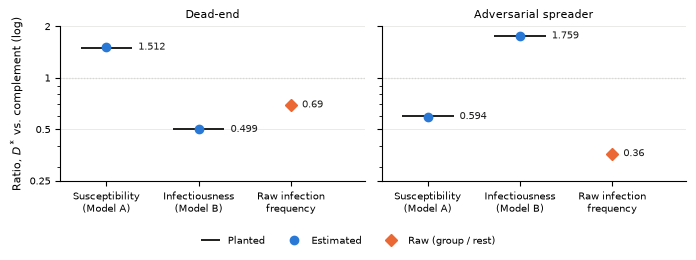

Saved figures/fig_cross_network.pdf


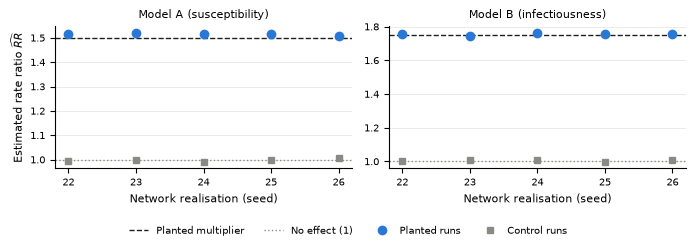

Saved figures/fig_ablations.pdf


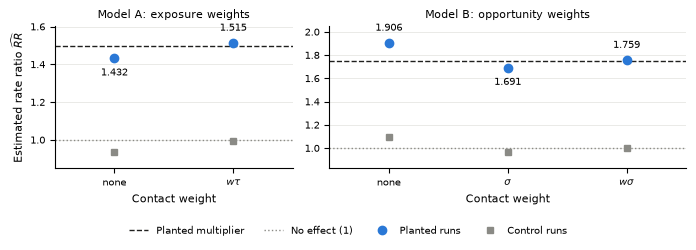

Saved figures/fig_naive_vs_adjusted.pdf


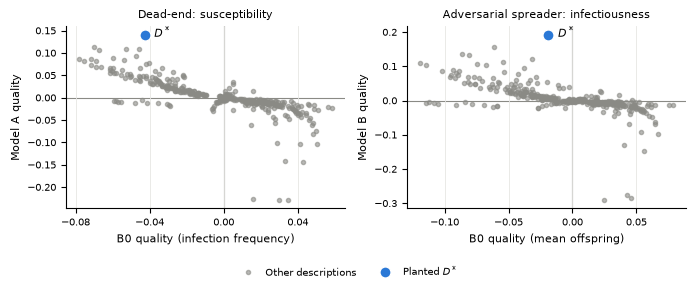

In [53]:
# ============================================================
# 12.3 Figures for the paper
#
# Sized for an ACM two-column layout (one column = 3.33 in).
# Colours: blue = planted / estimate, grey = control,
# orange = raw outcome; truth is a black line. Every series also
# differs in marker shape, so the figures work in greyscale.
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

COLOR_EST = "#2a78d6"
COLOR_RAW = "#eb6834"
COLOR_CTRL = "#8a8a85"
COLOR_TRUTH = "#1f1f1e"

plt.rcParams.update(
    {
        "font.size": 8,
        "axes.titlesize": 8,
        "axes.labelsize": 8,
        "legend.fontsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e6e6e3",
        "grid.linewidth": 0.6,
        "lines.linewidth": 1.2,
        "savefig.bbox": "tight",
        "savefig.dpi": 300,
    }
)


def save_figure(fig, name):
    for extension in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{extension}")
    print("Saved", FIG_DIR / f"{name}.pdf")


def bottom_legend(fig, ax, ncol):
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol, frameon=False)


def label_point(ax, x, value, text, above=True):
    """Value label above or below a marker, clear of horizontal reference lines."""
    ax.annotate(text, (x, value), xytext=(0, 7 if above else -7), textcoords="offset points",
                ha="center", va="bottom" if above else "top", fontsize=7)


def truth_tick(ax, x, value, half_width=0.28, **kwargs):
    ax.hlines(value, x - half_width, x + half_width, color=COLOR_TRUTH, linewidth=1.4, zorder=2, **kwargs)


# --- Figure 1: stress tests --------------------------------------------
# Per scenario: true vs estimated susceptibility and infectiousness
# ratios, next to the raw infection-frequency ratio of D* vs the rest.
stress_raw = {"Dead-end": dead_end_naive, "Adversarial spreader": adversarial_naive}

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.3), sharey=True)
categories = ["Susceptibility\n(Model A)", "Infectiousness\n(Model B)", "Raw infection\nfrequency"]

for ax, (_, row) in zip(axes, stress_test_summary.iterrows()):
    scenario = row["scenario"]
    truths = [row["true_susceptibility_rr"], row["true_infectiousness_rr"]]
    estimates = [row["estimated_model_a_rr"], row["estimated_model_b_rr"]]
    raw_ratio = stress_raw[scenario]["group"] / stress_raw[scenario]["rest"]

    for x, (truth, estimate) in enumerate(zip(truths, estimates)):
        truth_tick(ax, x, truth, label="Planted" if x == 0 else None)
        ax.plot(x, estimate, "o", color=COLOR_EST, markersize=6, zorder=3,
                label="Estimated" if x == 0 else None)
        ax.annotate(f"{estimate:.3f}", (x + 0.3, estimate), xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=7, color=COLOR_TRUTH)

    ax.plot(2, raw_ratio, "D", color=COLOR_RAW, markersize=6, zorder=3, label="Raw (group / rest)")
    ax.annotate(f"{raw_ratio:.2f}", (2, raw_ratio), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=7, color=COLOR_TRUTH)

    ax.axhline(1.0, color=COLOR_CTRL, linewidth=0.8, linestyle=":", zorder=1)
    ax.set_yscale("log")
    ax.set_xticks(range(3), categories)
    ax.set_xlim(-0.5, 2.8)
    ax.set_title(scenario)
    ax.set_yticks([0.25, 0.5, 1, 2], ["0.25", "0.5", "1", "2"])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())

axes[0].set_ylabel("Ratio, $D^*$ vs. complement (log)")
fig.tight_layout()
bottom_legend(fig, axes[0], ncol=3)
save_figure(fig, "fig_stress_tests")
plt.show()


# --- Figure 2: cross-network recovery --------------------------------
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.2))
panels = [
    ("Model A (susceptibility)", "A", NETWORK_MODEL_A_MULTIPLIER),
    ("Model B (infectiousness)", "B", NETWORK_MODEL_B_MULTIPLIER),
]

for ax, (title, model, truth) in zip(axes, panels):
    data = cross_network_ranks_df.query("model == @model")
    planted = data.query("condition == 'planted'")
    control = data.query("condition == 'control'")
    x = np.arange(len(planted))

    ax.axhline(truth, color=COLOR_TRUTH, linewidth=1.0, linestyle="--", label="Planted multiplier")
    ax.axhline(1.0, color=COLOR_CTRL, linewidth=1.0, linestyle=":", label="No effect (1)")
    ax.plot(x, planted["rate_ratio"], "o", color=COLOR_EST, markersize=6, label="Planted runs")
    ax.plot(x, control["rate_ratio"], "s", color=COLOR_CTRL, markersize=5, label="Control runs")

    ax.set_xticks(x, [str(s) for s in planted["network_seed"]])
    ax.set_xlabel("Network realisation (seed)")
    ax.set_title(title)

axes[0].set_ylabel(r"Estimated rate ratio $\widehat{RR}$")
fig.tight_layout()
bottom_legend(fig, axes[0], ncol=4)
save_figure(fig, "fig_cross_network")
plt.show()


# --- Figure 3: weighting ablations -----------------------------------
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.2), gridspec_kw={"width_ratios": [2, 3]})

ablation_panels = [
    (
        "Model A: exposure weights",
        model_a_exposure_ablation.rename(columns={"exposure": "method"}),
        {"Raw": "none", "Weighted": r"$w\tau$"},
        NETWORK_MODEL_A_MULTIPLIER,
    ),
    (
        "Model B: opportunity weights",
        model_b_weighting_ablation,
        {"Raw opportunity": "none", "Susceptibility weighted": r"$\sigma$",
         "Susceptibility + edge weighted": r"$w\sigma$"},
        NETWORK_MODEL_B_MULTIPLIER,
    ),
]

for ax, (title, table, labels, truth) in zip(axes, ablation_panels):
    methods = list(labels)
    x = np.arange(len(methods))
    planted = table.query("condition == 'Planted'").set_index("method").loc[methods, "rate_ratio"]
    control = table.query("condition == 'Control'").set_index("method").loc[methods, "rate_ratio"]

    ax.axhline(truth, color=COLOR_TRUTH, linewidth=1.0, linestyle="--", label="Planted multiplier")
    ax.axhline(1.0, color=COLOR_CTRL, linewidth=1.0, linestyle=":", label="No effect (1)")
    ax.plot(x, planted.to_numpy(), "o", color=COLOR_EST, markersize=6, label="Planted runs")
    ax.plot(x, control.to_numpy(), "s", color=COLOR_CTRL, markersize=5, label="Control runs")
    for xi, value in zip(x, planted.to_numpy()):
        label_point(ax, xi, value, f"{value:.3f}", above=value >= truth)

    ax.set_xticks(x, [labels[m] for m in methods])
    ax.set_xlim(-0.5, len(methods) - 0.5)
    ax.margins(y=0.15)
    ax.set_xlabel("Contact weight")
    ax.set_title(title)

axes[0].set_ylabel(r"Estimated rate ratio $\widehat{RR}$")
fig.tight_layout()
bottom_legend(fig, axes[0], ncol=4)
save_figure(fig, "fig_ablations")
plt.show()


# --- Figure 4: naive vs adjusted quality for every description --------
# Each point is one description; D* is highlighted. A method that
# separates D* puts it far from the cloud along its own axis.
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
scatter_panels = [
    ("Dead-end: susceptibility", ("Dead-end", "A", "B0", 0.5), dead_end_model_a_results,
     "B0 quality (infection frequency)", "Model A quality"),
    ("Adversarial spreader: infectiousness", ("Adversarial spreader", "B", "B0", 0.5),
     adversarial_model_b_results, "B0 quality (mean offspring)", "Model B quality"),
]

for ax, (title, key, adjusted, xlabel, ylabel) in zip(axes, scatter_panels):
    merged = naive_results_store[key][["description", "quality"]].merge(
        adjusted[["description", "quality"]], on="description", suffixes=("_naive", "_adjusted")
    )
    is_target = merged["description"] == STRESS_TARGET

    ax.axhline(0, color=COLOR_CTRL, linewidth=0.8, zorder=1)
    ax.axvline(0, color=COLOR_CTRL, linewidth=0.8, zorder=1)
    ax.plot(merged.loc[~is_target, "quality_naive"], merged.loc[~is_target, "quality_adjusted"],
            "o", color=COLOR_CTRL, markersize=3, alpha=0.6, label="Other descriptions")
    ax.plot(merged.loc[is_target, "quality_naive"], merged.loc[is_target, "quality_adjusted"],
            "o", color=COLOR_EST, markersize=8, markeredgecolor="white", markeredgewidth=1.0,
            zorder=3, label="Planted $D^*$")

    target = merged.loc[is_target].iloc[0]
    ax.annotate("$D^*$", (target["quality_naive"], target["quality_adjusted"]),
                xytext=(7, -2), textcoords="offset points", fontsize=8)

    ax.grid(axis="both")
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

fig.tight_layout()
bottom_legend(fig, axes[0], ncol=2)
save_figure(fig, "fig_naive_vs_adjusted")
plt.show()

### 12.4 Export


In [54]:
# ============================================================
# 12.4 Export every reported number to results.json
#
# The paper quotes numbers from this file only, so the text and
# the notebook cannot drift apart.
# ============================================================

import json


def _jsonable(value):
    if isinstance(value, pd.DataFrame):
        return [_jsonable(r) for r in value.to_dict(orient="records")]
    if isinstance(value, dict):
        return {str(k): _jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_jsonable(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, np.ndarray):
        return _jsonable(value.tolist())
    return value


household_size_counts = people.groupby("household_id").size().value_counts().sort_index()
household_type_counts = people.groupby("household_id")["household_type"].first().value_counts()

results = {
    "population": {
        "n_nodes": N_NODES,
        "n_households": int(people["household_id"].nunique()),
        "mean_household_size": float(people.groupby("household_id").size().mean()),
        "cbs_target_mean_household_size": float(np.sum(HOUSEHOLD_SIZES * HOUSEHOLD_SIZE_PROBS)),
        "households_by_size": household_size_counts.to_dict(),
        "households_by_type": household_type_counts.to_dict(),
        "household_size_comparison": comparison,
    },
    "network": {
        "household_transmission_multiplier": HOUSEHOLD_TRANSMISSION_MULTIPLIER,
        "realisations": network_summary,
    },
    "calibration": {
        "target_attack_rate": TARGET_ATTACK_RATE,
        "interval": [P_LOW, P_HIGH],
        "iterations": P_BISECTION_ITERATIONS,
        "runs_per_candidate": P_CALIBRATION_RUNS,
        "n_initial_infected": P_CALIBRATION_N_SEEDS,
        "calibrated_p": CALIBRATED_P,
        "history": calibration_history_df,
        "validation": {
            "runs": P_VALIDATION_RUNS,
            "mean": validation_attack_rates.mean(),
            "sd": validation_attack_rates.std(ddof=1),
            "median": np.median(validation_attack_rates),
            "min": validation_attack_rates.min(),
            "max": validation_attack_rates.max(),
        },
        "per_network": network_attack_summary,
    },
    "simulation": {
        "recovery_prob": RECOVERY_PROB,
        "minor_outbreak_threshold": MIN_MAJOR_ATTACK_RATE,
        "planted_description": STRESS_TARGET,
        "planted_size": int(planted_mask.sum()),
        "model_a_homogeneous_susceptibility": NETWORK_MODEL_A_BASE_SUSCEPTIBILITY,
    },
    "model_a_cross_network": {
        "true_rr": NETWORK_MODEL_A_MULTIPLIER,
        "per_network": network_model_a_summary,
        "mean_rr": network_model_a_summary["planted_target_rr"].mean(),
        "sd_rr": network_model_a_summary["planted_target_rr"].std(ddof=1),
        "mean_relative_error_pct": network_model_a_summary["relative_error_pct"].mean(),
        "mean_control_rr": network_model_a_summary["control_target_rr"].mean(),
        "mean_control_attack_rate": network_model_a_summary["control_attack_rate"].mean(),
    },
    "model_b_cross_network": {
        "true_rr": NETWORK_MODEL_B_MULTIPLIER,
        "per_network": network_model_b_summary,
        "mean_rr": network_model_b_summary["planted_target_rr"].mean(),
        "sd_rr": network_model_b_summary["planted_target_rr"].std(ddof=1),
        "mean_relative_error_pct": network_model_b_summary["relative_error_pct"].mean(),
        "mean_control_rr": network_model_b_summary["control_target_rr"].mean(),
        "mean_control_attack_rate": network_model_b_summary["control_attack_rate"].mean(),
    },
    "direction_free_ranks": cross_network_ranks_df,
    "stress_tests": {
        "summary": stress_test_summary,
        "raw_infection_frequency": {"dead_end": dead_end_naive, "adversarial": adversarial_naive},
    },
    "ablations": {
        "model_a": model_a_exposure_ablation,
        "model_b": model_b_weighting_ablation,
    },
    "naive_baselines": {
        "reference": NAIVE_REFERENCE,
        "comparison": naive_comparison,
        "control_top5_b0": control_naive_b0.head(5),
        "control_top5_b0plus": control_naive_b0plus.head(5),
        "control_top5_model_a": control_model_a.head(5)[["description", "rate_ratio", "quality"]],
    },
    "sanity": sanity,
}

RESULTS_PATH = Path("results.json")
RESULTS_PATH.write_text(json.dumps(_jsonable(results), indent=2))
print("Wrote", RESULTS_PATH.resolve())
print("Figures in", FIG_DIR.resolve())

Wrote /home/jarl/projects/sir-graph-emm/notebooks/results.json
Figures in /home/jarl/projects/sir-graph-emm/notebooks/figures


## 13. Local discretisation (final analysis)

Re-runs every search with **local** discretisation of age: equal-frequency cut points (`N_BINS = 10`) computed on the subgroup being refined. Requires the updated `sir_graph/emm.py`. Reuses all runs from Sections 6–11; no new simulations.

The exact planted description is usually not in the description space, so recovery is measured by Jaccard overlap with $G^*$ (recovered if $J \geq 0.8$). `gstar_rr` is the estimate for the exact planted group, which does not depend on the search.


### 13.1 Description space


In [55]:
# ============================================================
# 13.1 Local discretisation: description space
#
# Age cut points are N_BINS equal-frequency bins computed on the
# subgroup being refined: on the whole population at depth 1, and
# within the categorical condition when age refines it at depth 2.
# The exact planted description (age >= 60) is therefore usually not
# in the space, so recovery is measured by Jaccard overlap with G*.
# ============================================================

from sir_graph.emm import generate_descriptions, equal_frequency_cut_points

N_BINS = 10
JACCARD_RECOVERED = 0.8
MIN_SIZE = 200
LOCAL_COLUMNS = ["sex", "occupation", "smoking", "alcohol", "obesity"]

local_descriptions = generate_descriptions(
    people,
    categorical_columns=LOCAL_COLUMNS,
    age_column="age",
    max_depth=2,
    discretisation="local",
    n_bins=N_BINS,
)

local_mask = {d.description: d.mask for d in local_descriptions}

local_eval_masks = {
    description: mask
    for description, mask in local_mask.items()
    if MIN_SIZE <= mask.sum() <= N_NODES - MIN_SIZE
}


def jaccard(a, b):
    union = np.count_nonzero(a | b)
    return np.count_nonzero(a & b) / union if union else 0.0


ages_all = people["age"].to_numpy()
root_cut_points = equal_frequency_cut_points(ages_all, N_BINS)
smoker_cut_points = equal_frequency_cut_points(ages_all[people["smoking"].to_numpy() == 1], N_BINS)

best_possible_description, best_possible_mask = max(
    local_eval_masks.items(), key=lambda item: jaccard(item[1], planted_mask)
)

print("Descriptions generated:", len(local_mask))
print("Descriptions evaluable (both sides >= MIN_SIZE):", len(local_eval_masks))
print("Root age cut points:", root_cut_points)
print("Age cut points within smoking == 1:", smoker_cut_points)
print(
    "Closest description to G*:",
    best_possible_description,
    f"(Jaccard {jaccard(best_possible_mask, planted_mask):.3f}, size {best_possible_mask.sum()})",
)

Descriptions generated: 444
Descriptions evaluable (both sides >= MIN_SIZE): 414
Root age cut points: [8.0, 15.0, 22.0, 30.0, 37.0, 44.0, 52.0, 59.0, 67.0]
Age cut points within smoking == 1: [8.0, 15.0, 22.0, 30.0, 37.0, 44.0, 52.0, 59.0, 67.0]
Closest description to G*: smoking == 1 AND age >= 59 (Jaccard 0.927, size 1252)


### 13.2 Helpers


In [56]:
# ============================================================
# 13.2 Helpers: local searches and Jaccard-based recovery
# ============================================================


def local_search_a(observations, direction):
    return search_model_a_subgroups(
        people,
        observations,
        categorical_columns=LOCAL_COLUMNS,
        age_column="age",
        min_size=MIN_SIZE,
        max_depth=2,
        direction=direction,
        exposure_type="weighted",
        descriptions=local_descriptions,
    )


def local_search_b(observations, direction):
    return search_model_b_subgroups(
        people,
        observations,
        categorical_columns=LOCAL_COLUMNS,
        age_column="age",
        min_size=MIN_SIZE,
        max_depth=2,
        direction=direction,
        opportunity_type="weighted",
        descriptions=local_descriptions,
    )


def recovery_summary(ranked, target_mask=None):
    """Recovery of G* from results ordered best-first in the search direction."""
    if target_mask is None:
        target_mask = planted_mask
    ranked = ranked.reset_index(drop=True)
    overlap = np.array([jaccard(local_mask[d], target_mask) for d in ranked["description"]])
    hits = np.flatnonzero(overlap >= JACCARD_RECOVERED)
    has_rr = "rate_ratio" in ranked.columns
    top = ranked.iloc[0]
    first = int(hits[0]) if hits.size else None
    return {
        "n_descriptions": len(ranked),
        "top1_description": top["description"],
        "top1_size": int(local_mask[top["description"]].sum()),
        "top1_jaccard": float(overlap[0]),
        "top1_rr": float(top["rate_ratio"]) if has_rr else np.nan,
        "top5_best_jaccard": float(overlap[:5].max()),
        "recovered_rank": first + 1 if first is not None else None,
        "recovered_description": ranked.iloc[first]["description"] if first is not None else None,
        "recovered_jaccard": float(overlap[first]) if first is not None else np.nan,
        "recovered_rr": float(ranked.iloc[first]["rate_ratio"]) if (first is not None and has_rr) else np.nan,
    }

### 13.3 Recovery across networks


In [57]:
# ============================================================
# 13.3 Recovery across the five network realisations (local search)
#
# Reuses the matched runs of Sections 6-7; no new simulations.
# gstar_rr is the estimate for the exact planted group G*, which
# does not depend on the search.
# ============================================================

local_recovery_rows = []
local_cross_results = {}

for network_seed in NETWORK_REALISATION_SEEDS:
    current_graph = network_realisations[network_seed]["graph"]
    current_edge_multipliers = network_realisations[network_seed]["edge_multipliers"]

    for condition in ("planted", "control"):
        # Model A
        params_a = network_model_a_planted_params if condition == "planted" else network_model_a_base_params
        obs_a = model_a_observations(
            current_graph,
            network_model_a_results[network_seed][f"{condition}_runs"],
            infectiousness=params_a.infectiousness,
            edge_multipliers=current_edge_multipliers,
        )
        res_a = local_search_a(obs_a, "high")
        gstar_a = score_model_a_subgroup(planted_mask, obs_a, min_size=MIN_SIZE, direction="high", exposure_type="weighted")
        local_cross_results[("A", network_seed, condition)] = res_a
        local_recovery_rows.append(
            {"model": "A", "network_seed": network_seed, "condition": condition,
             "gstar_rr": gstar_a["rate_ratio"], **recovery_summary(res_a)}
        )

        # Model B
        obs_b = model_b_observations(
            current_graph,
            network_model_b_results[network_seed][f"{condition}_runs"],
            susceptibility=infection_rate,
            edge_multipliers=current_edge_multipliers,
        )
        res_b = local_search_b(obs_b, "high")
        gstar_b = score_model_b_subgroup(planted_mask, obs_b, min_size=MIN_SIZE, direction="high", opportunity_type="weighted")
        local_cross_results[("B", network_seed, condition)] = res_b
        local_recovery_rows.append(
            {"model": "B", "network_seed": network_seed, "condition": condition,
             "gstar_rr": gstar_b["rate_ratio"], **recovery_summary(res_b)}
        )

    print("Network", network_seed, "done")

local_recovery = pd.DataFrame(local_recovery_rows)

display(
    local_recovery[
        ["model", "network_seed", "condition", "top1_description", "top1_size", "top1_jaccard",
         "top1_rr", "recovered_rank", "gstar_rr"]
    ]
)

for model, truth in [("A", NETWORK_MODEL_A_MULTIPLIER), ("B", NETWORK_MODEL_B_MULTIPLIER)]:
    planted = local_recovery.query("model == @model and condition == 'planted'")
    control = local_recovery.query("model == @model and condition == 'control'")
    print(
        f"\nModel {model} (planted {truth}):"
        f"\n  top-1 has Jaccard >= {JACCARD_RECOVERED} on {int((planted['top1_jaccard'] >= JACCARD_RECOVERED).sum())}/{len(planted)} networks"
        f"\n  top-1 descriptions: {planted['top1_description'].value_counts().to_dict()}"
        f"\n  mean top-1 Jaccard {planted['top1_jaccard'].mean():.3f}, mean top-1 RR {planted['top1_rr'].mean():.4f}"
        f"\n  mean RR of G* {planted['gstar_rr'].mean():.4f} (SD {planted['gstar_rr'].std(ddof=1):.4f})"
        f"\n  control: largest top-1 RR {control['top1_rr'].max():.4f}, mean G* RR {control['gstar_rr'].mean():.4f}"
    )

Network 22 done
Network 23 done
Network 24 done
Network 25 done
Network 26 done


,model,network_seed,condition,top1_description,top1_size,top1_jaccard,top1_rr,recovered_rank,gstar_rr
0,A,22,planted,smoking == 1 AND age >= 59,1252,0.927316,1.456395,1,1.514720
1,B,22,planted,smoking == 1 AND age >= 59,1252,0.927316,1.662585,1,1.758581
2,A,22,control,age < 59,7895,0.000000,1.010189,332,0.994828
3,B,22,control,sex == Female AND age < 37,1936,0.000000,1.013132,112,1.003664
4,A,23,planted,smoking == 1 AND age >= 59,1252,0.927316,1.463440,1,1.520609
5,B,23,planted,smoking == 1 AND age >= 59,1252,0.927316,1.656836,1,1.747220
6,A,23,control,obesity == 0,9291,0.114880,1.008358,269,0.998810
7,B,23,control,smoking == 1,5989,0.193855,1.008787,11,1.007698
8,A,24,planted,smoking == 1 AND age >= 59,1252,0.927316,1.462236,1,1.515930
9,B,24,planted,smoking == 1 AND age >= 59,1252,0.927316,1.678023,1,1.763434



Model A (planted 1.5):
  top-1 has Jaccard >= 0.8 on 5/5 networks
  top-1 descriptions: {'smoking == 1 AND age >= 59': 5}
  mean top-1 Jaccard 0.927, mean top-1 RR 1.4583
  mean RR of G* 1.5149 (SD 0.0041)
  control: largest top-1 RR 1.0365, mean G* RR 0.9982

Model B (planted 1.75):
  top-1 has Jaccard >= 0.8 on 5/5 networks
  top-1 descriptions: {'smoking == 1 AND age >= 59': 5}
  mean top-1 Jaccard 0.927, mean top-1 RR 1.6645
  mean RR of G* 1.7571 (SD 0.0060)
  control: largest top-1 RR 1.0195, mean G* RR 1.0057


### 13.4 Stress tests


In [58]:
# ============================================================
# 13.4 Stress tests with the local search
#
# "given":   each model uses the planted value of the other mechanism.
# "assumed": each model assumes baseline values (tau = 1 for Model A,
#            the homogeneous baseline sigma for Model B), as an analyst
#            without that knowledge would.
# ============================================================

stress_cases = [
    ("Dead-end", dead_end_runs_filtered, dead_end_params, DEAD_END_SUSCEPTIBILITY, DEAD_END_INFECTIOUSNESS),
    ("Adversarial spreader", adversarial_runs_filtered, adversarial_params, ADVERSARIAL_SUSCEPTIBILITY, ADVERSARIAL_INFECTIOUSNESS),
]

local_stress_rows = []
local_stress_results = {}

for scenario, runs, params, true_sigma, true_tau in stress_cases:
    for knowledge, tau_used, sigma_used in [
        ("given", params.infectiousness, params.susceptibility),
        ("assumed", np.ones(N_NODES), stress_base_params.susceptibility),
    ]:
        direction_a = "high" if true_sigma > 1 else "low"
        obs_a = model_a_observations(graph, runs, infectiousness=tau_used, edge_multipliers=edge_multipliers)
        res_a = local_search_a(obs_a, direction_a)
        gstar_a = score_model_a_subgroup(planted_mask, obs_a, min_size=MIN_SIZE, direction=direction_a, exposure_type="weighted")
        local_stress_results[(scenario, "A", knowledge)] = res_a
        local_stress_rows.append(
            {"scenario": scenario, "model": "A", "knowledge": knowledge, "true": true_sigma,
             "gstar_rr": gstar_a["rate_ratio"], **recovery_summary(res_a)}
        )

        direction_b = "high" if true_tau > 1 else "low"
        obs_b = model_b_observations(graph, runs, susceptibility=sigma_used, edge_multipliers=edge_multipliers)
        res_b = local_search_b(obs_b, direction_b)
        gstar_b = score_model_b_subgroup(planted_mask, obs_b, min_size=MIN_SIZE, direction=direction_b, opportunity_type="weighted")
        local_stress_results[(scenario, "B", knowledge)] = res_b
        local_stress_rows.append(
            {"scenario": scenario, "model": "B", "knowledge": knowledge, "true": true_tau,
             "gstar_rr": gstar_b["rate_ratio"], **recovery_summary(res_b)}
        )

local_stress = pd.DataFrame(local_stress_rows)

display(
    local_stress[
        ["scenario", "model", "knowledge", "true", "gstar_rr", "top1_description",
         "top1_jaccard", "top1_rr", "recovered_rank"]
    ]
)

,scenario,model,knowledge,true,gstar_rr,top1_description,top1_jaccard,top1_rr,recovered_rank
0,Dead-end,A,given,1.50,1.512266,smoking == 1 AND age >= 59,0.927316,1.452063,1
1,Dead-end,B,given,0.50,0.499124,smoking == 1 AND age >= 59,0.927316,0.547425,1
2,Dead-end,A,assumed,1.50,1.373285,smoking == 1 AND age >= 59,0.927316,1.327264,1
3,Dead-end,B,assumed,0.50,0.545802,smoking == 1 AND age >= 59,0.927316,0.595786,1
4,Adversarial spreader,A,given,0.60,0.593887,smoking == 1 AND age >= 59,0.927316,0.631218,1
5,Adversarial spreader,B,given,1.75,1.759439,smoking == 1 AND age >= 59,0.927316,1.601408,1
6,Adversarial spreader,A,assumed,0.60,0.635900,smoking == 1 AND age >= 59,0.927316,0.673254,1
7,Adversarial spreader,B,assumed,1.75,1.606030,smoking == 1 AND age >= 59,0.927316,1.476782,1


### 13.5 Naive baselines


In [59]:
# ============================================================
# 13.5 Naive baselines B0 / B0+ on the same local description space
#
# Ranked in the direction of the planted effect, as the adjusted
# models are. gstar_sign_ok checks whether the naive quality of the
# exact planted group G* has the sign of the planted effect.
# Uses naive_targets / naive_degree from Section 11.
# ============================================================

naive_cases = [
    ("Dead-end", "A", "infection_frequency", DEAD_END_SUSCEPTIBILITY),
    ("Dead-end", "B", "mean_offspring", DEAD_END_INFECTIOUSNESS),
    ("Adversarial spreader", "A", "infection_frequency", ADVERSARIAL_SUSCEPTIBILITY),
    ("Adversarial spreader", "B", "mean_offspring", ADVERSARIAL_INFECTIOUSNESS),
]

local_naive_rows = []
local_naive_results = {}

for scenario, model, target, true_effect in naive_cases:
    high = true_effect > 1
    y_raw = naive_targets[scenario][target].to_numpy()
    y_resid, _ = residualise_on_degree(y_raw, naive_degree)

    for baseline, y in [("B0", y_raw), ("B0+", y_resid)]:
        results = naive_search(y, local_eval_masks, alpha=0.5, reference=NAIVE_REFERENCE, min_size=MIN_SIZE)
        ranked = results.sort_values("quality", ascending=not high, kind="stable").reset_index(drop=True)
        local_naive_results[(scenario, model, baseline)] = ranked
        gstar_quality, _, _ = naive_quality(planted_mask, y, alpha=0.5, reference=NAIVE_REFERENCE)
        local_naive_rows.append(
            {"scenario": scenario, "model": model, "target": target, "true": true_effect,
             "method": baseline, "gstar_quality": gstar_quality,
             "gstar_sign_ok": bool(np.sign(gstar_quality) == np.sign(np.log(true_effect))),
             **recovery_summary(ranked)}
        )

    for knowledge in ("given", "assumed"):
        adjusted = local_stress_results[(scenario, model, knowledge)]
        local_naive_rows.append(
            {"scenario": scenario, "model": model, "target": target, "true": true_effect,
             "method": f"Model {model} ({knowledge})", "gstar_quality": np.nan, "gstar_sign_ok": True,
             **recovery_summary(adjusted)}
        )

local_naive = pd.DataFrame(local_naive_rows)

display(
    local_naive[
        ["scenario", "model", "true", "method", "gstar_sign_ok", "top1_description",
         "top1_jaccard", "recovered_rank", "n_descriptions"]
    ]
)

,scenario,model,true,method,gstar_sign_ok,top1_description,top1_jaccard,recovered_rank,n_descriptions
0,Dead-end,A,1.50,B0,False,age < 15,0.000000,382,414
1,Dead-end,A,1.50,B0+,True,age < 15,0.000000,104,414
2,Dead-end,A,1.50,Model A (given),True,smoking == 1 AND age >= 59,0.927316,1,414
3,Dead-end,A,1.50,Model A (assumed),True,smoking == 1 AND age >= 59,0.927316,1,414
4,Dead-end,B,0.50,B0,True,age >= 59,0.551544,2,414
5,Dead-end,B,0.50,B0+,True,smoking == 1 AND age >= 59,0.927316,1,414
6,Dead-end,B,0.50,Model B (given),True,smoking == 1 AND age >= 59,0.927316,1,414
7,Dead-end,B,0.50,Model B (assumed),True,smoking == 1 AND age >= 59,0.927316,1,414
8,Adversarial spreader,A,0.60,B0,True,age >= 59,0.551544,4,414
9,Adversarial spreader,A,0.60,B0+,True,smoking == 1 AND age >= 59,0.927316,1,414


### 13.6 Exposure decoy


In [60]:
# ============================================================
# 13.6 Exposure decoy on the unplanted control runs (local search)
#
# No subgroup differs intrinsically. Both searches are ranked by
# effect size in either direction.
# ============================================================

local_decoy_naive = naive_search(control_y_raw, local_eval_masks, alpha=0.5, reference=NAIVE_REFERENCE, min_size=MIN_SIZE)

local_decoy_obs_a = model_a_observations(
    graph, dead_end_control_runs, infectiousness=stress_base_params.infectiousness, edge_multipliers=edge_multipliers
)
local_decoy_model_a = local_search_a(local_decoy_obs_a, "both")

print("B0 on control runs, top 5 by |quality|:")
display(local_decoy_naive.head(5)[["description", "size", "group_mean", "reference_mean", "quality"]])
print("Model A on control runs, top 5 by |log RR|:")
display(local_decoy_model_a.head(5)[["description", "size", "rate_ratio", "quality"]])

local_decoy_max_abs_log_rr = float(np.abs(np.log(local_decoy_model_a["rate_ratio"])).max())
print("Largest |log RR| of Model A on control runs:", local_decoy_max_abs_log_rr)

B0 on control runs, top 5 by |quality|:


,description,size,group_mean,reference_mean,quality
0,age >= 59,2105,0.262082,0.447887,-0.085248
1,obesity == 0 AND age >= 59,1965,0.262730,0.447887,-0.082077
2,age >= 52,3037,0.299745,0.447887,-0.081640
3,age >= 67,1004,0.191739,0.447887,-0.081163
4,obesity == 0 AND age >= 52,2826,0.300033,0.447887,-0.078599


Model A on control runs, top 5 by |log RR|:


,description,size,rate_ratio,quality
0,age >= 44 AND occupation == Sales and services,647,0.978863,0.005434
1,occupation == Sales and services AND age >= 45,626,0.979088,0.005288
2,occupation == Sales and services AND age >= 38,777,0.982393,0.004952
3,age >= 37 AND occupation == Sales and services,794,0.983395,0.004718
4,occupation == Sales and services AND age >= 30,934,0.985206,0.004555


Largest |log RR| of Model A on control runs: 0.021363195548136097


### 13.7 Figure


Saved figures/fig_naive_vs_adjusted_local.pdf


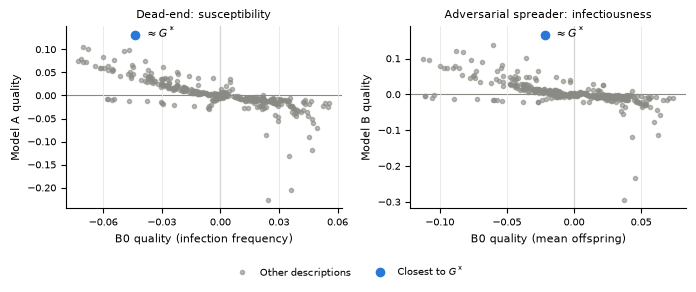

In [61]:
# ============================================================
# 13.7 Naive vs adjusted quality for every local description
# (replaces fig_naive_vs_adjusted). The description closest to G*
# is highlighted.
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
scatter_panels = [
    ("Dead-end: susceptibility", ("Dead-end", "A", "B0"), ("Dead-end", "A", "given"),
     "B0 quality (infection frequency)", "Model A quality"),
    ("Adversarial spreader: infectiousness", ("Adversarial spreader", "B", "B0"), ("Adversarial spreader", "B", "given"),
     "B0 quality (mean offspring)", "Model B quality"),
]

for ax, (title, naive_key, adjusted_key, xlabel, ylabel) in zip(axes, scatter_panels):
    merged = local_naive_results[naive_key][["description", "quality"]].merge(
        local_stress_results[adjusted_key][["description", "quality"]], on="description", suffixes=("_naive", "_adjusted")
    )
    overlap = merged["description"].map(lambda d: jaccard(local_mask[d], planted_mask))
    is_best = overlap == overlap.max()

    ax.axhline(0, color=COLOR_CTRL, linewidth=0.8, zorder=1)
    ax.axvline(0, color=COLOR_CTRL, linewidth=0.8, zorder=1)
    ax.plot(merged.loc[~is_best, "quality_naive"], merged.loc[~is_best, "quality_adjusted"],
            "o", color=COLOR_CTRL, markersize=3, alpha=0.6, label="Other descriptions")
    ax.plot(merged.loc[is_best, "quality_naive"], merged.loc[is_best, "quality_adjusted"],
            "o", color=COLOR_EST, markersize=8, markeredgecolor="white", markeredgewidth=1.0,
            zorder=3, label="Closest to $G^*$")

    best = merged.loc[is_best].iloc[0]
    ax.annotate("$\\approx G^*$", (best["quality_naive"], best["quality_adjusted"]),
                xytext=(7, -2), textcoords="offset points", fontsize=8)

    ax.grid(axis="both")
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

fig.tight_layout()
bottom_legend(fig, axes[0], ncol=2)
save_figure(fig, "fig_naive_vs_adjusted_local")
plt.show()

### 13.8 Export


In [62]:
# ============================================================
# 13.8 Export the local-discretisation results
# ============================================================

results_local = {
    "discretisation": {
        "type": "local equal-frequency",
        "n_bins": N_BINS,
        "jaccard_recovered": JACCARD_RECOVERED,
        "min_size": MIN_SIZE,
        "n_descriptions_generated": len(local_mask),
        "n_descriptions_evaluable": len(local_eval_masks),
        "root_age_cut_points": root_cut_points,
        "smoker_age_cut_points": smoker_cut_points,
        "closest_description": best_possible_description,
        "closest_jaccard": jaccard(best_possible_mask, planted_mask),
        "closest_size": int(best_possible_mask.sum()),
    },
    "cross_network": local_recovery,
    "stress_tests": local_stress,
    "naive_comparison": local_naive,
    "decoy": {
        "b0_top5": local_decoy_naive.head(5)[["description", "size", "group_mean", "reference_mean", "quality"]],
        "model_a_top5": local_decoy_model_a.head(5)[["description", "size", "rate_ratio", "quality"]],
        "model_a_max_abs_log_rr": local_decoy_max_abs_log_rr,
    },
}

Path("results_local.json").write_text(json.dumps(_jsonable(results_local), indent=2))
print("Wrote", Path("results_local.json").resolve())

Wrote /home/jarl/projects/sir-graph-emm/notebooks/results_local.json
